# SAMS Vision: safe and unsafe behaviour classification

This notebook trains image classifiers on the Voxel51 **Safe_and_Unsafe_Behaviours** dataset (eight workplace behaviour classes). SAMS does not load these weights in production today, but the notebook exports **`models/vision/safe_unsafe/best.pt`** and **`metadata.json`** for archival and future integration.

## Behaviour classes (8)

The dataset defines eight labels (authorized intervention, forklift overload, panel cover states, walkway compliance, and related behaviours). The notebook discovers the exact strings from dataset metadata and keeps a stable `label_to_idx` map in every export.

## Experiments

| Id | Architecture | Training recipe |
|----|--------------|-----------------|
| vision_exp01_tinycnn_scratch | TinyCNN | Train from scratch |
| vision_exp02_resnet18_frozen | ResNet18 | Frozen ImageNet backbone |
| vision_exp03_resnet18_finetune | ResNet18 | Full fine-tune, lower LR |
| vision_exp04_efficientnet_b0_frozen | EfficientNet-B0 | Frozen backbone |
| vision_exp05_mobilenet_v3_small | MobileNetV3-Small | Frozen backbone |
| vision_exp06_efficientnet_robust | EfficientNet-B0 | Class weights + stronger augmentation |

## Steps

| Section | Step |
|---------|------|
| 0 | Setup, configuration, helpers |
| 1 | Download Hugging Face snapshot |
| 2 | EDA, class previews, PCA |
| 3 | Extract frames to class folders |
| 4 | DataLoaders and training utilities (early stopping on val macro-F1) |
| 5 | Experiments |
| 6 | Compare, promote best, model card |
| 7 | Limitations |

## Rules

1. Frames from the published train/test splits stay in their split; validation is carved from train.
2. Early stopping uses **validation macro-F1** with configurable patience.
3. Every table is saved as CSV; charts as PNG.
4. No optional run flags - the full suite runs sequentially.

## 0. Setup

### 0.1 Paths

In [27]:
from pathlib import Path

IN_COLAB = False
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

print("Running in Colab:", IN_COLAB)

if IN_COLAB:
    SAMS_ROOT = Path("/content/SAMS")
else:
    SAMS_ROOT = Path("./SAMS_runtime")

for folder in [
    SAMS_ROOT / "datasets" / "vision" / "safe_unsafe",
    SAMS_ROOT / "models" / "vision" / "safe_unsafe",
    SAMS_ROOT / "results" / "vision" / "safe_unsafe",
]:
    folder.mkdir(parents=True, exist_ok=True)

Running in Colab: True


In [28]:
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_ROOT = Path("/content/drive/MyDrive/SAMS")
else:
    here = Path.cwd().resolve()
    if (here / "manage.py").exists():
        DRIVE_ROOT = here
    elif (here.parent / "manage.py").exists():
        DRIVE_ROOT = here.parent
    else:
        DRIVE_ROOT = Path("./SAMS_drive_mirror")

MODELS_DIR = DRIVE_ROOT / "models" / "vision" / "safe_unsafe"
RESULTS_DIR = DRIVE_ROOT / "results" / "vision" / "safe_unsafe"
DATA_DIR = SAMS_ROOT / "datasets" / "vision" / "safe_unsafe"
FRAMES_DIR = DATA_DIR / "frames"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### 0.2 Packages

In [29]:
import subprocess, sys
PACKAGES = [
    "pandas", "numpy", "matplotlib", "seaborn", "scikit-learn", "torch", "torchvision",
    "tqdm", "Pillow", "opencv-python-headless", "huggingface_hub", "datasets", "albumentations",
]
if IN_COLAB:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *PACKAGES])

In [30]:
import gc
import json
import random
import time
import warnings
from datetime import datetime, timezone
from pathlib import Path
from typing import Any, Dict, List, Optional

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
from torchvision import models, transforms
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")

### 0.3 Configuration

In [31]:
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_ROOT = Path("/content/drive/MyDrive/SAMS")
else:
    here = Path.cwd().resolve()
    if (here / "manage.py").exists():
        DRIVE_ROOT = here
    elif (here.parent / "manage.py").exists():
        DRIVE_ROOT = here.parent
    else:
        DRIVE_ROOT = Path("./SAMS_drive_mirror")

MODELS_DIR = DRIVE_ROOT / "models" / "vision" / "safe_unsafe"
RESULTS_DIR = DRIVE_ROOT / "results" / "vision" / "safe_unsafe"
DATA_DIR = SAMS_ROOT / "datasets" / "vision" / "safe_unsafe"

for folder in [MODELS_DIR, RESULTS_DIR, DATA_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("MODELS_DIR: ", MODELS_DIR)
print("RESULTS_DIR:", RESULTS_DIR)
print("DATA_DIR:   ", DATA_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
MODELS_DIR:  /content/drive/MyDrive/SAMS/models/vision/safe_unsafe
RESULTS_DIR: /content/drive/MyDrive/SAMS/results/vision/safe_unsafe
DATA_DIR:    /content/SAMS/datasets/vision/safe_unsafe


### 0.4 Helpers

In [32]:
def save_table(frame: pd.DataFrame, name: str) -> None:
    path = RESULTS_DIR / f"{name}.csv"
    frame.to_csv(path)
    display(frame)


HYPERPARAMS: Dict[str, pd.DataFrame] = {}


def register_hyperparams(exp_id: str, rows: List[Dict[str, Any]]) -> None:
    frame = pd.DataFrame(rows)
    HYPERPARAMS[exp_id] = frame
    save_table(frame.set_index("parameter"), f"hyperparams_{exp_id}")

## 1. Download dataset snapshot

We use `huggingface_hub.snapshot_download` for `Voxel51/Safe_and_Unsafe_Behaviours` and read clip metadata from the bundled CSV / Parquet files.

In [33]:
# --- Load via Hugging Face Hub  ---------------------------------
from huggingface_hub import snapshot_download

HF_REPO = "Voxel51/Safe_and_Unsafe_Behaviours"
DATASET_DIR = SAMS_ROOT / "datasets" / "vision" / "safe_unsafe" / "hf_snapshot"
DATASET_DIR.mkdir(parents=True, exist_ok=True)

print("Downloading dataset snapshot (videos + samples.json)...")
local_dir = snapshot_download(
    repo_id=HF_REPO,
    repo_type="dataset",
    local_dir=str(DATASET_DIR),
)
DATASET_DIR = Path(local_dir)
print("Dataset dir:", DATASET_DIR)

samples_path = DATASET_DIR / "samples.json"
assert samples_path.exists(), f"Missing {samples_path}"

with open(samples_path) as f:
    samples_blob = json.load(f)

raw_samples = samples_blob["samples"] if isinstance(samples_blob, dict) else samples_blob
print("Num samples:", len(raw_samples))
print("First label:", raw_samples[0].get("ground_truth", {}).get("label"))
print("First tags:", raw_samples[0].get("tags"))

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 698 files:   0%|          | 0/698 [00:00<?, ?it/s]

Dataset dir: /content/SAMS/datasets/vision/safe_unsafe/hf_snapshot
Num samples: 691
First label: Safe Walkway Violation
First tags: ['train']


## 2. Class list and exploratory analysis

Load metadata, map eight behaviour classes, show counts, preview frames per class, and PCA of simple image statistics or backbone embeddings.

In [34]:
# --- Inspect splits, classes, build meta_df ----------------------------------
rows = []
for s in raw_samples:
    gt = (s.get("ground_truth") or {}).get("label")
    tags = s.get("tags") or []
    split = "train" if "train" in tags else ("test" if "test" in tags else "unknown")
    rel = s.get("filepath")
    abs_path = str((DATASET_DIR / rel).resolve()) if rel else None
    md = s.get("metadata") or {}
    rows.append({
        "label": gt,
        "split": split,
        "filepath": abs_path,
        "relpath": rel,
        "duration": md.get("duration"),
        "fps": md.get("frame_rate"),
        "width": md.get("frame_width"),
        "height": md.get("frame_height"),
        "n_frames": md.get("total_frame_count"),
        "size_bytes": md.get("size_bytes"),
    })

meta_df = pd.DataFrame(rows)
print(meta_df.head())
print("\nSplit counts:\n", meta_df["split"].value_counts())
print("\nLabel counts:\n", meta_df["label"].value_counts())
print("\nLabel x split:\n", pd.crosstab(meta_df["label"], meta_df["split"]))

UNSAFE_CLASSES = {
    "Safe Walkway Violation",
    "Unauthorized Intervention",
    "Opened Panel Cover",
    "Carrying Overload with Forklift",
}
SAFE_CLASSES = {
    "Safe Walkway",
    "Authorized Intervention",
    "Closed Panel Cover",
    "Safe Carrying",
}

CLASS_NAMES = sorted(meta_df["label"].dropna().unique().tolist())
label_to_idx = {c: i for i, c in enumerate(CLASS_NAMES)}
idx_to_label = {i: c for c, i in label_to_idx.items()}
print("\nCLASS_NAMES:", CLASS_NAMES)
print("Num classes:", len(CLASS_NAMES))

missing = meta_df["filepath"].map(lambda p: not Path(p).exists()).sum()
print("Missing video files:", int(missing))

                    label  split  \
0  Safe Walkway Violation  train   
1  Safe Walkway Violation  train   
2  Safe Walkway Violation  train   
3  Safe Walkway Violation  train   
4  Safe Walkway Violation  train   

                                            filepath           relpath  \
0  /content/SAMS/datasets/vision/safe_unsafe/hf_s...    data/0_tr1.mp4   
1  /content/SAMS/datasets/vision/safe_unsafe/hf_s...   data/0_tr10.mp4   
2  /content/SAMS/datasets/vision/safe_unsafe/hf_s...  data/0_tr100.mp4   
3  /content/SAMS/datasets/vision/safe_unsafe/hf_s...  data/0_tr101.mp4   
4  /content/SAMS/datasets/vision/safe_unsafe/hf_s...  data/0_tr102.mp4   

    duration    fps  width  height  n_frames  size_bytes  
0  14.015304  24.83   1920    1080       348    25865947  
1  15.022151  24.83   1920    1080       373    29372683  
2   8.014499  24.83   1920    1080       199    14633315  
3   8.014499  24.83   1920    1080       199    14612449  
4   8.014499  24.83   1920    1080       19

In [35]:
# EDA tables
eda_df = meta_df.copy()
save_table(eda_df["label"].value_counts().rename("clips"), "eda_clips_per_class")
save_table(pd.crosstab(eda_df["label"], eda_df["split"]), "eda_clips_by_split")

,clips
label,
Safe Walkway Violation,210
Opened Panel Cover,142
Unauthorized Intervention,108
Safe Walkway,75
Carrying Overload with Forklift,56
Authorized Intervention,38
Closed Panel Cover,32
Safe Carrying,30


split,test,train
label,,
Authorized Intervention,15,23
Carrying Overload with Forklift,8,48
Closed Panel Cover,13,19
Opened Panel Cover,13,129
Safe Carrying,8,22
Safe Walkway,25,50
Safe Walkway Violation,32,178
Unauthorized Intervention,11,97


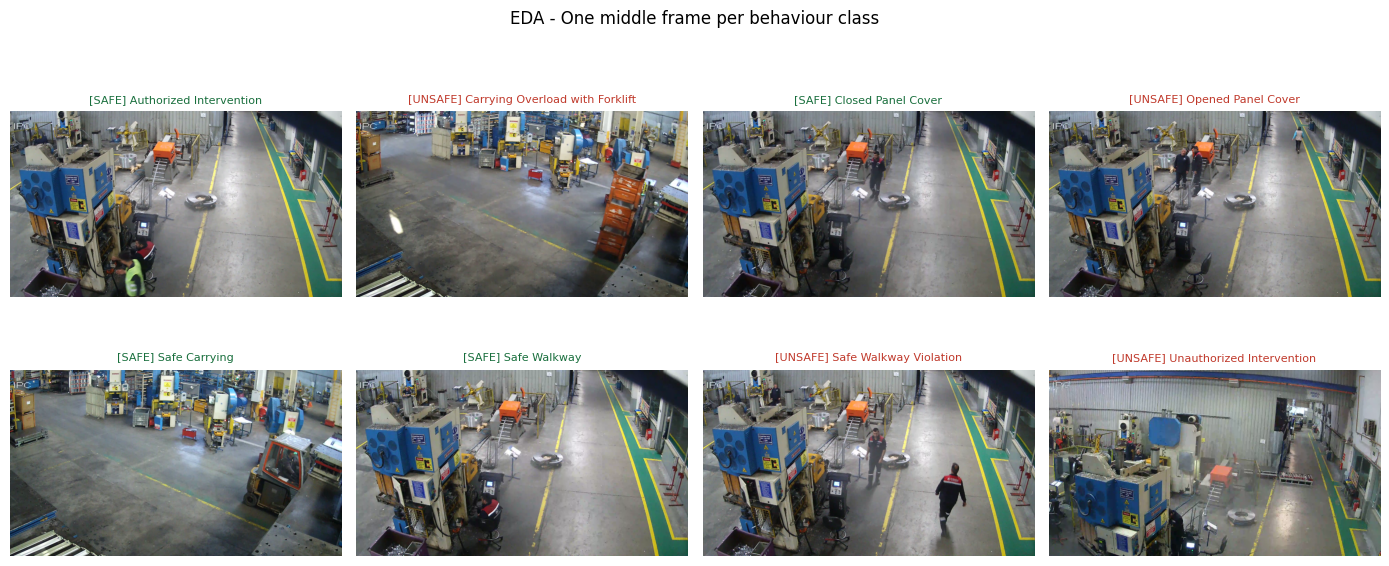

Saved: /content/drive/MyDrive/SAMS/results/vision/safe_unsafe/eda/per_class_gallery.png


In [36]:
# --- EDA 4: Per-class visual gallery (1 middle frame each) -------------------
EDA_DIR = RESULTS_DIR / "eda"
EDA_DIR.mkdir(parents=True, exist_ok=True)


def middle_frame_bgr(video_path: str):
    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        return None
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT) or 0)
    if total > 0:
        cap.set(cv2.CAP_PROP_POS_FRAMES, total // 2)
    ok, frame = cap.read()
    cap.release()
    return frame if ok else None


n_classes = len(CLASS_NAMES)
cols = 4
rows = int(np.ceil(n_classes / cols))
fig, axes = plt.subplots(rows, cols, figsize=(14, 3.2 * rows))
axes = np.array(axes).reshape(-1)

for ax, cls in zip(axes, CLASS_NAMES):
    subset = eda_df[eda_df["label"] == cls]
    if subset.empty:
        ax.set_title(cls[:30] + " (empty)")
        ax.axis("off")
        continue
    path = subset.sample(1, random_state=42).iloc[0]["filepath"]
    frame = middle_frame_bgr(str(path))
    if frame is None:
        ax.set_title(cls[:30] + " (read fail)")
        ax.axis("off")
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    ax.imshow(rgb)
    kind = "UNSAFE" if cls in UNSAFE_CLASSES else "SAFE"
    ax.set_title(f"[{kind}] {cls}", fontsize=8, color=("#c0392b" if kind == "UNSAFE" else "#196f3d"))
    ax.axis("off")

for ax in axes[n_classes:]:
    ax.axis("off")

plt.suptitle("EDA - One middle frame per behaviour class", fontsize=12)
plt.tight_layout()
fig_path = EDA_DIR / "per_class_gallery.png"
plt.savefig(fig_path, dpi=140, bbox_inches="tight")
plt.show()
print("Saved:", fig_path)

### 2.1 PCA of ResNet18 embeddings

Embed one frame per class with a frozen ResNet18 trunk and plot the first two principal components. This shows whether the eight behaviour classes already separate before any SAMS training.

In [39]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED = globals().get("SEED", 42)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print("DEVICE:", DEVICE)

DEVICE: cuda


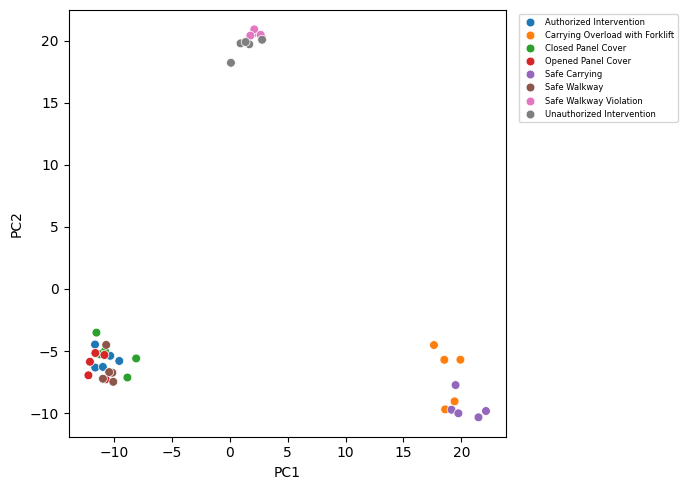

In [40]:
from PIL import Image


@torch.no_grad()
def embed_paths(paths: List[Path], limit: int = 40) -> np.ndarray:
    tfm = transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    ])
    trunk = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    trunk.fc = nn.Identity()
    trunk = trunk.to(DEVICE).eval()
    vecs = []
    for p in paths[:limit]:
        img = tfm(Image.open(p).convert("RGB")).unsqueeze(0).to(DEVICE)
        vecs.append(trunk(img).cpu().numpy()[0])
    return np.stack(vecs, axis=0)


# will run after frames exist; guard for first-time order
manifest_path = FRAMES_DIR / "manifest.csv"
if manifest_path.exists():
    manifest = pd.read_csv(manifest_path)
    sample_paths = []
    labels = []
    for cls in CLASS_NAMES:
        sub = manifest[manifest["label"] == cls].head(5)
        sample_paths.extend([Path(p) for p in sub["filepath"]])
        labels.extend([cls] * len(sub))
    if sample_paths:
        emb = embed_paths(sample_paths, limit=len(sample_paths))
        coords = PCA(n_components=2, random_state=SEED).fit_transform(StandardScaler().fit_transform(emb))
        pca_df = pd.DataFrame({"PC1": coords[:, 0], "PC2": coords[:, 1], "label": labels})
        fig, ax = plt.subplots(figsize=(7, 5))
        sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="label", s=40, ax=ax)
        ax.legend(fontsize=6, bbox_to_anchor=(1.02, 1), loc="upper left")
        plt.tight_layout()
        plt.savefig(RESULTS_DIR / "pca_resnet18_embeddings.png", dpi=140)
        plt.show()
else:
    print("No frame manifest yet - run the frame extraction cell first, then re-run this one.")

## 3. Frame extraction

Extract JPEG frames into `frames/{train,test}/<class>/` and write `manifest.csv`.

In [41]:
def extract_frames(
    video_path: str,
    out_dir: Path,
    stem: str,
    max_frames: int = 4,
) -> list[Path]:
    """Extract up to `max_frames` evenly spaced frames from a video."""
    out_dir.mkdir(parents=True, exist_ok=True)
    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        return []

    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT) or 0)
    if total <= 0:
        frames = []
        idx = 0
        while True:
            ok, frame = cap.read()
            if not ok:
                break
            frames.append((idx, frame))
            idx += 1
            if idx > 300:
                break
        total = len(frames)
        if total == 0:
            cap.release()
            return []
        indices = np.linspace(0, total - 1, num=min(max_frames, total), dtype=int)
        saved = []
        for j, i in enumerate(indices):
            path = out_dir / f"{stem}_f{j:02d}.jpg"
            cv2.imwrite(str(path), frames[i][1])
            saved.append(path)
        cap.release()
        return saved

    indices = np.linspace(0, total - 1, num=min(max_frames, total), dtype=int)
    saved = []
    for j, frame_idx in enumerate(indices):
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(frame_idx))
        ok, frame = cap.read()
        if not ok:
            continue
        path = out_dir / f"{stem}_f{j:02d}.jpg"
        cv2.imwrite(str(path), frame)
        saved.append(path)
    cap.release()
    return saved


MAX_FRAMES_PER_VIDEO = 3
MAX_VIDEOS_PER_SPLIT: int | None = None

manifest_path = FRAMES_DIR / "manifest.csv"

if manifest_path.exists():
    frame_manifest = pd.read_csv(manifest_path)
    print("Reusing existing frame manifest:", manifest_path)
    print(frame_manifest.shape)
else:
    records = []
    for split_name in ["train", "test"]:
        subset = meta_df[meta_df["split"] == split_name]
        if MAX_VIDEOS_PER_SPLIT is not None:
            subset = subset.head(MAX_VIDEOS_PER_SPLIT)
        print(f"Extracting frames for split={split_name} (n_videos={len(subset)})...")
        for _, row in tqdm(subset.iterrows(), total=len(subset)):
            label = row["label"]
            if pd.isna(label) or not row["filepath"]:
                continue
            safe_label = str(label).replace("/", "_").replace(" ", "_")
            out_dir = FRAMES_DIR / split_name / safe_label
            stem = Path(row["filepath"]).stem
            paths = extract_frames(row["filepath"], out_dir, stem, max_frames=MAX_FRAMES_PER_VIDEO)
            for p in paths:
                records.append({
                    "filepath": str(p),
                    "split": split_name,
                    "label": label,
                    "label_idx": label_to_idx[label],
                    "binary": "unsafe" if label in UNSAFE_CLASSES else "safe",
                    "source_video": row["filepath"],
                })

    frame_manifest = pd.DataFrame(records)
    frame_manifest.to_csv(manifest_path, index=False)
    print("Saved manifest:", manifest_path)
    print(frame_manifest.groupby(["split", "label"]).size())

print(frame_manifest.head())
print("Total frames:", len(frame_manifest))

Reusing existing frame manifest: /content/SAMS/datasets/vision/safe_unsafe/frames/manifest.csv
(2059, 6)
                                            filepath  split  \
0  /content/SAMS/datasets/vision/safe_unsafe/fram...  train   
1  /content/SAMS/datasets/vision/safe_unsafe/fram...  train   
2  /content/SAMS/datasets/vision/safe_unsafe/fram...  train   
3  /content/SAMS/datasets/vision/safe_unsafe/fram...  train   
4  /content/SAMS/datasets/vision/safe_unsafe/fram...  train   

                    label  label_idx  binary  \
0  Safe Walkway Violation          6  unsafe   
1  Safe Walkway Violation          6  unsafe   
2  Safe Walkway Violation          6  unsafe   
3  Safe Walkway Violation          6  unsafe   
4  Safe Walkway Violation          6  unsafe   

                                        source_video  
0  /content/SAMS/datasets/vision/safe_unsafe/hf_s...  
1  /content/SAMS/datasets/vision/safe_unsafe/hf_s...  
2  /content/SAMS/datasets/vision/safe_unsafe/hf_s...  
3  /con

## 4. Models, data loaders, training with early stopping

Training stops when validation macro-F1 does not improve for `PATIENCE` epochs.

In [42]:
class TinyCNN(nn.Module):
    """Small CNN trained from scratch - Experiment 1 baseline."""

    def __init__(self, num_classes: int):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(128, 256, 3, padding=1), nn.BatchNorm2d(256), nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d(1),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.4),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


def build_resnet18(num_classes: int, freeze_backbone: bool = True) -> nn.Module:
    weights = models.ResNet18_Weights.IMAGENET1K_V1
    model = models.resnet18(weights=weights)
    if freeze_backbone:
        for p in model.parameters():
            p.requires_grad = False
    in_features = model.fc.in_features
    model.fc = nn.Linear(in_features, num_classes)
    return model


def build_efficientnet_b0(num_classes: int, freeze_backbone: bool = True) -> nn.Module:
    weights = models.EfficientNet_B0_Weights.IMAGENET1K_V1
    model = models.efficientnet_b0(weights=weights)
    if freeze_backbone:
        for p in model.parameters():
            p.requires_grad = False
    in_features = model.classifier[1].in_features
    model.classifier[1] = nn.Linear(in_features, num_classes)
    return model


def build_mobilenet_v3_small(num_classes: int, freeze_backbone: bool = True) -> nn.Module:
    weights = models.MobileNet_V3_Small_Weights.IMAGENET1K_V1
    model = models.mobilenet_v3_small(weights=weights)
    if freeze_backbone:
        for p in model.parameters():
            p.requires_grad = False
    in_features = model.classifier[3].in_features
    model.classifier[3] = nn.Linear(in_features, num_classes)
    return model


NUM_CLASSES = len(CLASS_NAMES)
print("NUM_CLASSES:", NUM_CLASSES)

NUM_CLASSES: 8


In [43]:
class TinyCNN(nn.Module):
    """Small CNN trained from scratch - Experiment 1 baseline."""

    def __init__(self, num_classes: int):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(128, 256, 3, padding=1), nn.BatchNorm2d(256), nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d(1),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.4),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


def build_resnet18(num_classes: int, freeze_backbone: bool = True) -> nn.Module:
    weights = models.ResNet18_Weights.IMAGENET1K_V1
    model = models.resnet18(weights=weights)
    if freeze_backbone:
        for p in model.parameters():
            p.requires_grad = False
    in_features = model.fc.in_features
    model.fc = nn.Linear(in_features, num_classes)
    return model


def build_efficientnet_b0(num_classes: int, freeze_backbone: bool = True) -> nn.Module:
    weights = models.EfficientNet_B0_Weights.IMAGENET1K_V1
    model = models.efficientnet_b0(weights=weights)
    if freeze_backbone:
        for p in model.parameters():
            p.requires_grad = False
    in_features = model.classifier[1].in_features
    model.classifier[1] = nn.Linear(in_features, num_classes)
    return model


def build_mobilenet_v3_small(num_classes: int, freeze_backbone: bool = True) -> nn.Module:
    weights = models.MobileNet_V3_Small_Weights.IMAGENET1K_V1
    model = models.mobilenet_v3_small(weights=weights)
    if freeze_backbone:
        for p in model.parameters():
            p.requires_grad = False
    in_features = model.classifier[3].in_features
    model.classifier[3] = nn.Linear(in_features, num_classes)
    return model


NUM_CLASSES = len(CLASS_NAMES)
print("NUM_CLASSES:", NUM_CLASSES)

NUM_CLASSES: 8


In [44]:
class TinyCNN(nn.Module):
    """Small CNN trained from scratch - Experiment 1 baseline."""

    def __init__(self, num_classes: int):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(128, 256, 3, padding=1), nn.BatchNorm2d(256), nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d(1),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.4),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


def build_resnet18(num_classes: int, freeze_backbone: bool = True) -> nn.Module:
    weights = models.ResNet18_Weights.IMAGENET1K_V1
    model = models.resnet18(weights=weights)
    if freeze_backbone:
        for p in model.parameters():
            p.requires_grad = False
    in_features = model.fc.in_features
    model.fc = nn.Linear(in_features, num_classes)
    return model


def build_efficientnet_b0(num_classes: int, freeze_backbone: bool = True) -> nn.Module:
    weights = models.EfficientNet_B0_Weights.IMAGENET1K_V1
    model = models.efficientnet_b0(weights=weights)
    if freeze_backbone:
        for p in model.parameters():
            p.requires_grad = False
    in_features = model.classifier[1].in_features
    model.classifier[1] = nn.Linear(in_features, num_classes)
    return model


def build_mobilenet_v3_small(num_classes: int, freeze_backbone: bool = True) -> nn.Module:
    weights = models.MobileNet_V3_Small_Weights.IMAGENET1K_V1
    model = models.mobilenet_v3_small(weights=weights)
    if freeze_backbone:
        for p in model.parameters():
            p.requires_grad = False
    in_features = model.classifier[3].in_features
    model.classifier[3] = nn.Linear(in_features, num_classes)
    return model


NUM_CLASSES = len(CLASS_NAMES)
print("NUM_CLASSES:", NUM_CLASSES)

NUM_CLASSES: 8


In [45]:
class TinyCNN(nn.Module):
    """Small CNN trained from scratch - Experiment 1 baseline."""

    def __init__(self, num_classes: int):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(128, 256, 3, padding=1), nn.BatchNorm2d(256), nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d(1),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.4),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


def build_resnet18(num_classes: int, freeze_backbone: bool = True) -> nn.Module:
    weights = models.ResNet18_Weights.IMAGENET1K_V1
    model = models.resnet18(weights=weights)
    if freeze_backbone:
        for p in model.parameters():
            p.requires_grad = False
    in_features = model.fc.in_features
    model.fc = nn.Linear(in_features, num_classes)
    return model


def build_efficientnet_b0(num_classes: int, freeze_backbone: bool = True) -> nn.Module:
    weights = models.EfficientNet_B0_Weights.IMAGENET1K_V1
    model = models.efficientnet_b0(weights=weights)
    if freeze_backbone:
        for p in model.parameters():
            p.requires_grad = False
    in_features = model.classifier[1].in_features
    model.classifier[1] = nn.Linear(in_features, num_classes)
    return model


def build_mobilenet_v3_small(num_classes: int, freeze_backbone: bool = True) -> nn.Module:
    weights = models.MobileNet_V3_Small_Weights.IMAGENET1K_V1
    model = models.mobilenet_v3_small(weights=weights)
    if freeze_backbone:
        for p in model.parameters():
            p.requires_grad = False
    in_features = model.classifier[3].in_features
    model.classifier[3] = nn.Linear(in_features, num_classes)
    return model


NUM_CLASSES = len(CLASS_NAMES)
print("NUM_CLASSES:", NUM_CLASSES)

NUM_CLASSES: 8


In [46]:
from typing import Any, Dict, List, Optional, Tuple

IMG_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 2

train_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

# Stronger augmentation (used by experiment 6)
strong_train_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE + 32, IMG_SIZE + 32)),
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.2),
    transforms.RandomRotation(12),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

eval_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])


class FrameDataset(Dataset):
    def __init__(self, df: pd.DataFrame, transform=None):
        self.df = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self) -> int:
        return len(self.df)

    def __getitem__(self, idx: int):
        row = self.df.iloc[idx]
        img = Image.open(row["filepath"]).convert("RGB")
        if self.transform:
            img = self.transform(img)
        y = int(row["label_idx"])
        return img, y


def make_loaders(
    manifest: pd.DataFrame,
    train_transform=train_tfms,
    batch_size: int = BATCH_SIZE,
    use_weighted_sampler: bool = False,
) -> Dict[str, Any]:
    train_df = manifest[manifest["split"] == "train"].copy()
    test_df = manifest[manifest["split"] == "test"].copy()
    # Hold out 15% of train frames as validation (by video stem when possible)
    train_df["stem"] = train_df["filepath"].map(lambda p: Path(p).stem.rsplit("_f", 1)[0])
    stems = train_df["stem"].unique()
    rng = np.random.RandomState(42)
    rng.shuffle(stems)
    n_val = max(1, int(0.15 * len(stems)))
    val_stems = set(stems[:n_val])
    val_df = train_df[train_df["stem"].isin(val_stems)].drop(columns=["stem"])
    train_df = train_df[~train_df["stem"].isin(val_stems)].drop(columns=["stem"])

    train_ds = FrameDataset(train_df, transform=train_transform)
    val_ds = FrameDataset(val_df, transform=eval_tfms)
    test_ds = FrameDataset(test_df, transform=eval_tfms)

    sampler = None
    shuffle = True
    if use_weighted_sampler:
        counts = train_df["label_idx"].value_counts().to_dict()
        weights = train_df["label_idx"].map(lambda i: 1.0 / counts[i]).values
        sampler = WeightedRandomSampler(weights, num_samples=len(weights), replacement=True)
        shuffle = False

    train_loader = DataLoader(
        train_ds, batch_size=batch_size, shuffle=shuffle, sampler=sampler,
        num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available(),
    )
    val_loader = DataLoader(
        val_ds, batch_size=batch_size, shuffle=False,
        num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available(),
    )
    test_loader = DataLoader(
        test_ds, batch_size=batch_size, shuffle=False,
        num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available(),
    )
    return {
        "train": train_loader,
        "val": val_loader,
        "test": test_loader,
        "train_df": train_df,
        "val_df": val_df,
        "test_df": test_df,
    }


def compute_metrics(y_true: np.ndarray, y_pred: np.ndarray, class_names: List[str]) -> Dict[str, Any]:
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "precision_macro": float(precision_score(y_true, y_pred, average="macro", zero_division=0)),
        "recall_macro": float(recall_score(y_true, y_pred, average="macro", zero_division=0)),
        "f1_macro": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
        "precision_weighted": float(precision_score(y_true, y_pred, average="weighted", zero_division=0)),
        "recall_weighted": float(recall_score(y_true, y_pred, average="weighted", zero_division=0)),
        "f1_weighted": float(f1_score(y_true, y_pred, average="weighted", zero_division=0)),
        "f1_per_class": {
            class_names[i]: float(v)
            for i, v in enumerate(f1_score(y_true, y_pred, average=None, zero_division=0, labels=list(range(len(class_names)))))
        },
        "classification_report": classification_report(
            y_true, y_pred, labels=list(range(len(class_names))), target_names=class_names, zero_division=0
        ),
        "confusion_matrix": confusion_matrix(y_true, y_pred, labels=list(range(len(class_names)))).tolist(),
    }


@torch.no_grad()
def evaluate(model: nn.Module, loader: DataLoader, device: torch.device, class_names: List[str]) -> Dict[str, Any]:
    model.eval()
    ys, preds = [], []
    for x, y in loader:
        x = x.to(device, non_blocking=True)
        logits = model(x)
        pred = logits.argmax(dim=1).cpu().numpy()
        ys.append(y.numpy())
        preds.append(pred)
    y_true = np.concatenate(ys)
    y_pred = np.concatenate(preds)
    return compute_metrics(y_true, y_pred, class_names)


def train_one_experiment(
    model: nn.Module,
    loaders: Dict[str, Any],
    *,
    experiment_id: str,
    approach: str,
    epochs: int,
    lr: float,
    weight_decay: float = 1e-4,
    class_weights: Optional[torch.Tensor] = None,
    device: torch.device = DEVICE,
    class_names: Optional[List[str]] = None,
) -> Tuple[nn.Module, Dict[str, Any]]:
    class_names = class_names or CLASS_NAMES
    model = model.to(device)
    criterion = nn.CrossEntropyLoss(weight=class_weights.to(device) if class_weights is not None else None)
    optimizer = optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=lr, weight_decay=weight_decay)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=max(epochs, 1))

    history = {"train_loss": [], "val_loss": [], "val_f1_macro": [], "val_accuracy": []}
    best_f1 = -1.0
    best_state = None
    t0 = time.time()

    print("=" * 72)
    print(f"EXPERIMENT: {experiment_id}")
    print(f"APPROACH:   {approach}")
    print(f"Epochs={epochs}  LR={lr}  Device={device}")
    print("=" * 72)

    for epoch in range(1, epochs + 1):
        model.train()
        running = 0.0
        n = 0
        pbar = tqdm(loaders["train"], desc=f"[{experiment_id}] epoch {epoch}/{epochs}", leave=False)
        for x, y in pbar:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            logits = model(x)
            loss = criterion(logits, y)
            loss.backward()
            optimizer.step()
            running += loss.item() * x.size(0)
            n += x.size(0)
            pbar.set_postfix(loss=f"{loss.item():.4f}")
        scheduler.step()

        train_loss = running / max(n, 1)
        # val
        model.eval()
        v_running, v_n = 0.0, 0
        ys, preds = [], []
        with torch.no_grad():
            for x, y in loaders["val"]:
                x = x.to(device, non_blocking=True)
                y_dev = y.to(device, non_blocking=True)
                logits = model(x)
                loss = criterion(logits, y_dev)
                v_running += loss.item() * x.size(0)
                v_n += x.size(0)
                preds.append(logits.argmax(1).cpu().numpy())
                ys.append(y.numpy())
        val_loss = v_running / max(v_n, 1)
        y_true = np.concatenate(ys)
        y_pred = np.concatenate(preds)
        val_metrics = compute_metrics(y_true, y_pred, class_names)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_f1_macro"].append(val_metrics["f1_macro"])
        history["val_accuracy"].append(val_metrics["accuracy"])

        print(
            f"  epoch {epoch:02d} | train_loss={train_loss:.4f} | val_loss={val_loss:.4f} "
            f"| val_acc={val_metrics['accuracy']:.4f} | val_f1_macro={val_metrics['f1_macro']:.4f}"
        )

        if val_metrics["f1_macro"] > best_f1:
            best_f1 = val_metrics["f1_macro"]
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

    if best_state is not None:
        model.load_state_dict(best_state)

    test_metrics = evaluate(model, loaders["test"], device, class_names)
    elapsed = time.time() - t0

    print("\n--- Test metrics ---")
    print(f"Accuracy:          {test_metrics['accuracy']:.4f}")
    print(f"Precision (macro): {test_metrics['precision_macro']:.4f}")
    print(f"Recall (macro):    {test_metrics['recall_macro']:.4f}")
    print(f"F1 (macro):        {test_metrics['f1_macro']:.4f}")
    print(f"F1 (weighted):     {test_metrics['f1_weighted']:.4f}")
    print(test_metrics["classification_report"])

    result = {
        "experiment_id": experiment_id,
        "approach": approach,
        "epochs": epochs,
        "lr": lr,
        "weight_decay": weight_decay,
        "img_size": IMG_SIZE,
        "batch_size": BATCH_SIZE,
        "device": str(device),
        "elapsed_sec": elapsed,
        "class_names": class_names,
        "label_to_idx": label_to_idx,
        "best_val_f1_macro": best_f1,
        "history": history,
        "test_metrics": {k: v for k, v in test_metrics.items() if k != "classification_report"},
        "classification_report": test_metrics["classification_report"],
        "timestamp_utc": datetime.now(timezone.utc).isoformat(),
        "dataset": HF_REPO,
        "task": "multiclass_behaviour_classification",
        "num_classes": len(class_names),
    }
    return model, result


def save_experiment(model: nn.Module, result: Dict[str, Any], extra_meta: Optional[Dict] = None) -> Path:
    """Save weights + metadata sidecar together under Drive models/vision."""
    exp_id = result["experiment_id"]
    out_dir = MODELS_DIR / exp_id
    out_dir.mkdir(parents=True, exist_ok=True)
    RESULTS_DIR.mkdir(parents=True, exist_ok=True)

    weights_path = out_dir / "model.pt"
    meta_path = out_dir / "metadata.json"
    history_path = out_dir / "history.json"
    report_path = out_dir / "classification_report.txt"
    cm_path = out_dir / "confusion_matrix.png"

    meta = dict(result)
    if extra_meta:
        meta.update(extra_meta)
    # Don't duplicate large blobs oddly - history saved separately
    history = meta.pop("history", {})
    report = meta.pop("classification_report", "")
    cm = np.array(meta.get("test_metrics", {}).get("confusion_matrix", []))

    torch.save(
        {
            "model_state_dict": model.state_dict(),
            "metadata": {k: v for k, v in meta.items() if k != "test_metrics"},
            "test_metrics": meta.get("test_metrics"),
            "class_names": result["class_names"],
            "label_to_idx": result["label_to_idx"],
        },
        weights_path,
    )

    with open(meta_path, "w") as f:
        json.dump(meta, f, indent=2)
    with open(history_path, "w") as f:
        json.dump(history, f, indent=2)
    with open(report_path, "w") as f:
        f.write(report)

    if cm.size:
        plt.figure(figsize=(8, 6))
        sns.heatmap(
            cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=result["class_names"], yticklabels=result["class_names"],
        )
        plt.xticks(rotation=45, ha="right", fontsize=7)
        plt.yticks(fontsize=7)
        plt.xlabel("Predicted")
        plt.ylabel("True")
        plt.title(f"Confusion Matrix - {exp_id}")
        plt.tight_layout()
        plt.savefig(cm_path, dpi=140)
        plt.show()

    # Append to global results ledger
    ledger_path = RESULTS_DIR / "vision_experiment_ledger.csv"
    row = {
        "experiment_id": exp_id,
        "approach": result["approach"],
        "accuracy": result["test_metrics"]["accuracy"],
        "precision_macro": result["test_metrics"]["precision_macro"],
        "recall_macro": result["test_metrics"]["recall_macro"],
        "f1_macro": result["test_metrics"]["f1_macro"],
        "f1_weighted": result["test_metrics"]["f1_weighted"],
        "best_val_f1_macro": result["best_val_f1_macro"],
        "epochs": result["epochs"],
        "lr": result["lr"],
        "elapsed_sec": result["elapsed_sec"],
        "weights_path": str(weights_path),
        "metadata_path": str(meta_path),
        "timestamp_utc": result["timestamp_utc"],
    }
    ledger = pd.DataFrame([row])
    if ledger_path.exists():
        prev = pd.read_csv(ledger_path)
        # replace same experiment_id if re-run
        prev = prev[prev["experiment_id"] != exp_id]
        ledger = pd.concat([prev, ledger], ignore_index=True)
    ledger.to_csv(ledger_path, index=False)

    print(f"[SAVE] weights -> {weights_path}")
    print(f"[SAVE] metadata -> {meta_path}")
    print(f"[SAVE] ledger -> {ledger_path}")
    return out_dir


# Registry collected in-notebook for the final comparison table
EXPERIMENT_RESULTS: List[Dict[str, Any]] = []
print("Utilities ready.")

Utilities ready.


In [47]:
IMG_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 2

train_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

# Stronger augmentation (used by experiment 6)
strong_train_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE + 32, IMG_SIZE + 32)),
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.2),
    transforms.RandomRotation(12),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

eval_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])


class FrameDataset(Dataset):
    def __init__(self, df: pd.DataFrame, transform=None):
        self.df = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self) -> int:
        return len(self.df)

    def __getitem__(self, idx: int):
        row = self.df.iloc[idx]
        img = Image.open(row["filepath"]).convert("RGB")
        if self.transform:
            img = self.transform(img)
        y = int(row["label_idx"])
        return img, y


def make_loaders(
    manifest: pd.DataFrame,
    train_transform=train_tfms,
    batch_size: int = BATCH_SIZE,
    use_weighted_sampler: bool = False,
) -> Tuple[DataLoader, DataLoader, pd.DataFrame, pd.DataFrame]:
    train_df = manifest[manifest["split"] == "train"].copy()
    test_df = manifest[manifest["split"] == "test"].copy()
    # Hold out 15% of train frames as validation (by video stem when possible)
    train_df["stem"] = train_df["filepath"].map(lambda p: Path(p).stem.rsplit("_f", 1)[0])
    stems = train_df["stem"].unique()
    rng = np.random.RandomState(42)
    rng.shuffle(stems)
    n_val = max(1, int(0.15 * len(stems)))
    val_stems = set(stems[:n_val])
    val_df = train_df[train_df["stem"].isin(val_stems)].drop(columns=["stem"])
    train_df = train_df[~train_df["stem"].isin(val_stems)].drop(columns=["stem"])

    train_ds = FrameDataset(train_df, transform=train_transform)
    val_ds = FrameDataset(val_df, transform=eval_tfms)
    test_ds = FrameDataset(test_df, transform=eval_tfms)

    sampler = None
    shuffle = True
    if use_weighted_sampler:
        counts = train_df["label_idx"].value_counts().to_dict()
        weights = train_df["label_idx"].map(lambda i: 1.0 / counts[i]).values
        sampler = WeightedRandomSampler(weights, num_samples=len(weights), replacement=True)
        shuffle = False

    train_loader = DataLoader(
        train_ds, batch_size=batch_size, shuffle=shuffle, sampler=sampler,
        num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available(),
    )
    val_loader = DataLoader(
        val_ds, batch_size=batch_size, shuffle=False,
        num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available(),
    )
    test_loader = DataLoader(
        test_ds, batch_size=batch_size, shuffle=False,
        num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available(),
    )
    # stash loaders on a simple namespace-like dict
    return {
        "train": train_loader,
        "val": val_loader,
        "test": test_loader,
        "train_df": train_df,
        "val_df": val_df,
        "test_df": test_df,
    }


def compute_metrics(y_true: np.ndarray, y_pred: np.ndarray, class_names: List[str]) -> Dict[str, Any]:
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "precision_macro": float(precision_score(y_true, y_pred, average="macro", zero_division=0)),
        "recall_macro": float(recall_score(y_true, y_pred, average="macro", zero_division=0)),
        "f1_macro": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
        "precision_weighted": float(precision_score(y_true, y_pred, average="weighted", zero_division=0)),
        "recall_weighted": float(recall_score(y_true, y_pred, average="weighted", zero_division=0)),
        "f1_weighted": float(f1_score(y_true, y_pred, average="weighted", zero_division=0)),
        "f1_per_class": {
            class_names[i]: float(v)
            for i, v in enumerate(f1_score(y_true, y_pred, average=None, zero_division=0, labels=list(range(len(class_names)))))
        },
        "classification_report": classification_report(
            y_true, y_pred, target_names=class_names, zero_division=0
        ),
        "confusion_matrix": confusion_matrix(y_true, y_pred, labels=list(range(len(class_names)))).tolist(),
    }


@torch.no_grad()
def evaluate(model: nn.Module, loader: DataLoader, device: torch.device, class_names: List[str]) -> Dict[str, Any]:
    model.eval()
    ys, preds = [], []
    for x, y in loader:
        x = x.to(device, non_blocking=True)
        logits = model(x)
        pred = logits.argmax(dim=1).cpu().numpy()
        ys.append(y.numpy())
        preds.append(pred)
    y_true = np.concatenate(ys)
    y_pred = np.concatenate(preds)
    return compute_metrics(y_true, y_pred, class_names)


def train_one_experiment(
    model: nn.Module,
    loaders: Dict[str, Any],
    *,
    experiment_id: str,
    approach: str,
    epochs: int,
    lr: float,
    weight_decay: float = 1e-4,
    class_weights: Optional[torch.Tensor] = None,
    device: torch.device = DEVICE,
    class_names: List[str] = None,
) -> Dict[str, Any]:
    class_names = class_names or CLASS_NAMES
    model = model.to(device)
    criterion = nn.CrossEntropyLoss(weight=class_weights.to(device) if class_weights is not None else None)
    optimizer = optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=lr, weight_decay=weight_decay)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=max(epochs, 1))

    history = {"train_loss": [], "val_loss": [], "val_f1_macro": [], "val_accuracy": []}
    best_f1 = -1.0
    best_state = None
    bad_epochs = 0
    t0 = time.time()

    print("=" * 72)
    print(f"EXPERIMENT: {experiment_id}")
    print(f"APPROACH:   {approach}")
    print(f"Epochs={epochs}  LR={lr}  Device={device}")
    print("=" * 72)

    for epoch in range(1, epochs + 1):
        model.train()
        running = 0.0
        n = 0
        pbar = tqdm(loaders["train"], desc=f"[{experiment_id}] epoch {epoch}/{epochs}", leave=False)
        for x, y in pbar:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            logits = model(x)
            loss = criterion(logits, y)
            loss.backward()
            optimizer.step()
            running += loss.item() * x.size(0)
            n += x.size(0)
            pbar.set_postfix(loss=f"{loss.item():.4f}")
        scheduler.step()

        train_loss = running / max(n, 1)
        # val
        model.eval()
        v_running, v_n = 0.0, 0
        ys, preds = [], []
        with torch.no_grad():
            for x, y in loaders["val"]:
                x = x.to(device, non_blocking=True)
                y_dev = y.to(device, non_blocking=True)
                logits = model(x)
                loss = criterion(logits, y_dev)
                v_running += loss.item() * x.size(0)
                v_n += x.size(0)
                preds.append(logits.argmax(1).cpu().numpy())
                ys.append(y.numpy())
        val_loss = v_running / max(v_n, 1)
        y_true = np.concatenate(ys)
        y_pred = np.concatenate(preds)
        val_metrics = compute_metrics(y_true, y_pred, class_names)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_f1_macro"].append(val_metrics["f1_macro"])
        history["val_accuracy"].append(val_metrics["accuracy"])

        print(
            f"  epoch {epoch:02d} | train_loss={train_loss:.4f} | val_loss={val_loss:.4f} "
            f"| val_acc={val_metrics['accuracy']:.4f} | val_f1_macro={val_metrics['f1_macro']:.4f}"
        )

        if val_metrics["f1_macro"] > best_f1:
            best_f1 = val_metrics["f1_macro"]
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            bad_epochs = 0
        else:
            bad_epochs += 1
            if bad_epochs >= PATIENCE:
                print(f"Early stopping at epoch {epoch}")
                break

    if best_state is not None:
        model.load_state_dict(best_state)

    test_metrics = evaluate(model, loaders["test"], device, class_names)
    elapsed = time.time() - t0

    print("\n--- Test metrics ---")
    print(f"Accuracy:          {test_metrics['accuracy']:.4f}")
    print(f"Precision (macro): {test_metrics['precision_macro']:.4f}")
    print(f"Recall (macro):    {test_metrics['recall_macro']:.4f}")
    print(f"F1 (macro):        {test_metrics['f1_macro']:.4f}")
    print(f"F1 (weighted):     {test_metrics['f1_weighted']:.4f}")
    print(test_metrics["classification_report"])

    result = {
        "experiment_id": experiment_id,
        "approach": approach,
        "epochs": epochs,
        "lr": lr,
        "weight_decay": weight_decay,
        "img_size": IMG_SIZE,
        "batch_size": BATCH_SIZE,
        "device": str(device),
        "elapsed_sec": elapsed,
        "class_names": class_names,
        "label_to_idx": label_to_idx,
        "best_val_f1_macro": best_f1,
        "history": history,
        "test_metrics": {k: v for k, v in test_metrics.items() if k != "classification_report"},
        "classification_report": test_metrics["classification_report"],
        "timestamp_utc": datetime.now(timezone.utc).isoformat(),
        "dataset": HF_REPO,
        "task": "multiclass_behaviour_classification",
        "num_classes": len(class_names),
    }
    return model, result


def save_experiment(model: nn.Module, result: Dict[str, Any], extra_meta: Optional[Dict] = None) -> Path:
    """Save weights + metadata sidecar together under Drive models/vision."""
    exp_id = result["experiment_id"]
    out_dir = MODELS_DIR / exp_id
    out_dir.mkdir(parents=True, exist_ok=True)

    weights_path = out_dir / "model.pt"
    meta_path = out_dir / "metadata.json"
    history_path = out_dir / "history.json"
    report_path = out_dir / "classification_report.txt"
    cm_path = out_dir / "confusion_matrix.png"

    meta = dict(result)
    if extra_meta:
        meta.update(extra_meta)
    # Don't duplicate large blobs oddly - history saved separately
    history = meta.pop("history", {})
    report = meta.pop("classification_report", "")
    cm = np.array(meta.get("test_metrics", {}).get("confusion_matrix", []))

    torch.save(
        {
            "model_state_dict": model.state_dict(),
            "metadata": {k: v for k, v in meta.items() if k != "test_metrics"},
            "test_metrics": meta.get("test_metrics"),
            "class_names": result["class_names"],
            "label_to_idx": result["label_to_idx"],
        },
        weights_path,
    )

    with open(meta_path, "w") as f:
        json.dump(meta, f, indent=2)
    with open(history_path, "w") as f:
        json.dump(history, f, indent=2)
    with open(report_path, "w") as f:
        f.write(report)

    if cm.size:
        plt.figure(figsize=(8, 6))
        sns.heatmap(
            cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=result["class_names"], yticklabels=result["class_names"],
        )
        plt.xticks(rotation=45, ha="right", fontsize=7)
        plt.yticks(fontsize=7)
        plt.xlabel("Predicted")
        plt.ylabel("True")
        plt.title(f"Confusion Matrix - {exp_id}")
        plt.tight_layout()
        plt.savefig(cm_path, dpi=140)
        plt.show()

    # Append to global results ledger
    ledger_path = RESULTS_DIR / "vision_experiment_ledger.csv"
    row = {
        "experiment_id": exp_id,
        "approach": result["approach"],
        "accuracy": result["test_metrics"]["accuracy"],
        "precision_macro": result["test_metrics"]["precision_macro"],
        "recall_macro": result["test_metrics"]["recall_macro"],
        "f1_macro": result["test_metrics"]["f1_macro"],
        "f1_weighted": result["test_metrics"]["f1_weighted"],
        "best_val_f1_macro": result["best_val_f1_macro"],
        "epochs": result["epochs"],
        "lr": result["lr"],
        "elapsed_sec": result["elapsed_sec"],
        "weights_path": str(weights_path),
        "metadata_path": str(meta_path),
        "timestamp_utc": result["timestamp_utc"],
    }
    ledger = pd.DataFrame([row])
    if ledger_path.exists():
        prev = pd.read_csv(ledger_path)
        # replace same experiment_id if re-run
        prev = prev[prev["experiment_id"] != exp_id]
        ledger = pd.concat([prev, ledger], ignore_index=True)
    ledger.to_csv(ledger_path, index=False)

    print(f"[SAVE] weights -> {weights_path}")
    print(f"[SAVE] metadata -> {meta_path}")
    print(f"[SAVE] ledger -> {ledger_path}")
    return out_dir


# Registry collected in-notebook for the final comparison table
EXPERIMENT_RESULTS: List[Dict[str, Any]] = []
print("Utilities ready.")

Utilities ready.


In [48]:
IMG_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 2

train_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

# Stronger augmentation (used by experiment 6)
strong_train_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE + 32, IMG_SIZE + 32)),
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.2),
    transforms.RandomRotation(12),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

eval_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])


class FrameDataset(Dataset):
    def __init__(self, df: pd.DataFrame, transform=None):
        self.df = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self) -> int:
        return len(self.df)

    def __getitem__(self, idx: int):
        row = self.df.iloc[idx]
        img = Image.open(row["filepath"]).convert("RGB")
        if self.transform:
            img = self.transform(img)
        y = int(row["label_idx"])
        return img, y


def make_loaders(
    manifest: pd.DataFrame,
    train_transform=train_tfms,
    batch_size: int = BATCH_SIZE,
    use_weighted_sampler: bool = False,
) -> Tuple[DataLoader, DataLoader, pd.DataFrame, pd.DataFrame]:
    train_df = manifest[manifest["split"] == "train"].copy()
    test_df = manifest[manifest["split"] == "test"].copy()
    # Hold out 15% of train frames as validation (by video stem when possible)
    train_df["stem"] = train_df["filepath"].map(lambda p: Path(p).stem.rsplit("_f", 1)[0])
    stems = train_df["stem"].unique()
    rng = np.random.RandomState(42)
    rng.shuffle(stems)
    n_val = max(1, int(0.15 * len(stems)))
    val_stems = set(stems[:n_val])
    val_df = train_df[train_df["stem"].isin(val_stems)].drop(columns=["stem"])
    train_df = train_df[~train_df["stem"].isin(val_stems)].drop(columns=["stem"])

    train_ds = FrameDataset(train_df, transform=train_transform)
    val_ds = FrameDataset(val_df, transform=eval_tfms)
    test_ds = FrameDataset(test_df, transform=eval_tfms)

    sampler = None
    shuffle = True
    if use_weighted_sampler:
        counts = train_df["label_idx"].value_counts().to_dict()
        weights = train_df["label_idx"].map(lambda i: 1.0 / counts[i]).values
        sampler = WeightedRandomSampler(weights, num_samples=len(weights), replacement=True)
        shuffle = False

    train_loader = DataLoader(
        train_ds, batch_size=batch_size, shuffle=shuffle, sampler=sampler,
        num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available(),
    )
    val_loader = DataLoader(
        val_ds, batch_size=batch_size, shuffle=False,
        num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available(),
    )
    test_loader = DataLoader(
        test_ds, batch_size=batch_size, shuffle=False,
        num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available(),
    )
    # stash loaders on a simple namespace-like dict
    return {
        "train": train_loader,
        "val": val_loader,
        "test": test_loader,
        "train_df": train_df,
        "val_df": val_df,
        "test_df": test_df,
    }


def compute_metrics(y_true: np.ndarray, y_pred: np.ndarray, class_names: List[str]) -> Dict[str, Any]:
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "precision_macro": float(precision_score(y_true, y_pred, average="macro", zero_division=0)),
        "recall_macro": float(recall_score(y_true, y_pred, average="macro", zero_division=0)),
        "f1_macro": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
        "precision_weighted": float(precision_score(y_true, y_pred, average="weighted", zero_division=0)),
        "recall_weighted": float(recall_score(y_true, y_pred, average="weighted", zero_division=0)),
        "f1_weighted": float(f1_score(y_true, y_pred, average="weighted", zero_division=0)),
        "f1_per_class": {
            class_names[i]: float(v)
            for i, v in enumerate(f1_score(y_true, y_pred, average=None, zero_division=0, labels=list(range(len(class_names)))))
        },
        "classification_report": classification_report(
            y_true, y_pred, target_names=class_names, zero_division=0
        ),
        "confusion_matrix": confusion_matrix(y_true, y_pred, labels=list(range(len(class_names)))).tolist(),
    }


@torch.no_grad()
def evaluate(model: nn.Module, loader: DataLoader, device: torch.device, class_names: List[str]) -> Dict[str, Any]:
    model.eval()
    ys, preds = [], []
    for x, y in loader:
        x = x.to(device, non_blocking=True)
        logits = model(x)
        pred = logits.argmax(dim=1).cpu().numpy()
        ys.append(y.numpy())
        preds.append(pred)
    y_true = np.concatenate(ys)
    y_pred = np.concatenate(preds)
    return compute_metrics(y_true, y_pred, class_names)


def train_one_experiment(
    model: nn.Module,
    loaders: Dict[str, Any],
    *,
    experiment_id: str,
    approach: str,
    epochs: int,
    lr: float,
    weight_decay: float = 1e-4,
    class_weights: Optional[torch.Tensor] = None,
    device: torch.device = DEVICE,
    class_names: List[str] = None,
) -> Dict[str, Any]:
    class_names = class_names or CLASS_NAMES
    model = model.to(device)
    criterion = nn.CrossEntropyLoss(weight=class_weights.to(device) if class_weights is not None else None)
    optimizer = optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=lr, weight_decay=weight_decay)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=max(epochs, 1))

    history = {"train_loss": [], "val_loss": [], "val_f1_macro": [], "val_accuracy": []}
    best_f1 = -1.0
    best_state = None
    t0 = time.time()

    print("=" * 72)
    print(f"EXPERIMENT: {experiment_id}")
    print(f"APPROACH:   {approach}")
    print(f"Epochs={epochs}  LR={lr}  Device={device}")
    print("=" * 72)

    for epoch in range(1, epochs + 1):
        model.train()
        running = 0.0
        n = 0
        pbar = tqdm(loaders["train"], desc=f"[{experiment_id}] epoch {epoch}/{epochs}", leave=False)
        for x, y in pbar:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            logits = model(x)
            loss = criterion(logits, y)
            loss.backward()
            optimizer.step()
            running += loss.item() * x.size(0)
            n += x.size(0)
            pbar.set_postfix(loss=f"{loss.item():.4f}")
        scheduler.step()

        train_loss = running / max(n, 1)
        # val
        model.eval()
        v_running, v_n = 0.0, 0
        ys, preds = [], []
        with torch.no_grad():
            for x, y in loaders["val"]:
                x = x.to(device, non_blocking=True)
                y_dev = y.to(device, non_blocking=True)
                logits = model(x)
                loss = criterion(logits, y_dev)
                v_running += loss.item() * x.size(0)
                v_n += x.size(0)
                preds.append(logits.argmax(1).cpu().numpy())
                ys.append(y.numpy())
        val_loss = v_running / max(v_n, 1)
        y_true = np.concatenate(ys)
        y_pred = np.concatenate(preds)
        val_metrics = compute_metrics(y_true, y_pred, class_names)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_f1_macro"].append(val_metrics["f1_macro"])
        history["val_accuracy"].append(val_metrics["accuracy"])

        print(
            f"  epoch {epoch:02d} | train_loss={train_loss:.4f} | val_loss={val_loss:.4f} "
            f"| val_acc={val_metrics['accuracy']:.4f} | val_f1_macro={val_metrics['f1_macro']:.4f}"
        )

        if val_metrics["f1_macro"] > best_f1:
            best_f1 = val_metrics["f1_macro"]
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

    if best_state is not None:
        model.load_state_dict(best_state)

    test_metrics = evaluate(model, loaders["test"], device, class_names)
    elapsed = time.time() - t0

    print("\n--- Test metrics ---")
    print(f"Accuracy:          {test_metrics['accuracy']:.4f}")
    print(f"Precision (macro): {test_metrics['precision_macro']:.4f}")
    print(f"Recall (macro):    {test_metrics['recall_macro']:.4f}")
    print(f"F1 (macro):        {test_metrics['f1_macro']:.4f}")
    print(f"F1 (weighted):     {test_metrics['f1_weighted']:.4f}")
    print(test_metrics["classification_report"])

    result = {
        "experiment_id": experiment_id,
        "approach": approach,
        "epochs": epochs,
        "lr": lr,
        "weight_decay": weight_decay,
        "img_size": IMG_SIZE,
        "batch_size": BATCH_SIZE,
        "device": str(device),
        "elapsed_sec": elapsed,
        "class_names": class_names,
        "label_to_idx": label_to_idx,
        "best_val_f1_macro": best_f1,
        "history": history,
        "test_metrics": {k: v for k, v in test_metrics.items() if k != "classification_report"},
        "classification_report": test_metrics["classification_report"],
        "timestamp_utc": datetime.now(timezone.utc).isoformat(),
        "dataset": HF_REPO,
        "task": "multiclass_behaviour_classification",
        "num_classes": len(class_names),
    }
    return model, result


def save_experiment(model: nn.Module, result: Dict[str, Any], extra_meta: Optional[Dict] = None) -> Path:
    """Save weights + metadata sidecar together under Drive models/vision."""
    exp_id = result["experiment_id"]
    out_dir = MODELS_DIR / exp_id
    out_dir.mkdir(parents=True, exist_ok=True)

    weights_path = out_dir / "model.pt"
    meta_path = out_dir / "metadata.json"
    history_path = out_dir / "history.json"
    report_path = out_dir / "classification_report.txt"
    cm_path = out_dir / "confusion_matrix.png"

    meta = dict(result)
    if extra_meta:
        meta.update(extra_meta)
    # Don't duplicate large blobs oddly - history saved separately
    history = meta.pop("history", {})
    report = meta.pop("classification_report", "")
    cm = np.array(meta.get("test_metrics", {}).get("confusion_matrix", []))

    torch.save(
        {
            "model_state_dict": model.state_dict(),
            "metadata": {k: v for k, v in meta.items() if k != "test_metrics"},
            "test_metrics": meta.get("test_metrics"),
            "class_names": result["class_names"],
            "label_to_idx": result["label_to_idx"],
        },
        weights_path,
    )

    with open(meta_path, "w") as f:
        json.dump(meta, f, indent=2)
    with open(history_path, "w") as f:
        json.dump(history, f, indent=2)
    with open(report_path, "w") as f:
        f.write(report)

    if cm.size:
        plt.figure(figsize=(8, 6))
        sns.heatmap(
            cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=result["class_names"], yticklabels=result["class_names"],
        )
        plt.xticks(rotation=45, ha="right", fontsize=7)
        plt.yticks(fontsize=7)
        plt.xlabel("Predicted")
        plt.ylabel("True")
        plt.title(f"Confusion Matrix - {exp_id}")
        plt.tight_layout()
        plt.savefig(cm_path, dpi=140)
        plt.show()

    # Append to global results ledger
    ledger_path = RESULTS_DIR / "vision_experiment_ledger.csv"
    row = {
        "experiment_id": exp_id,
        "approach": result["approach"],
        "accuracy": result["test_metrics"]["accuracy"],
        "precision_macro": result["test_metrics"]["precision_macro"],
        "recall_macro": result["test_metrics"]["recall_macro"],
        "f1_macro": result["test_metrics"]["f1_macro"],
        "f1_weighted": result["test_metrics"]["f1_weighted"],
        "best_val_f1_macro": result["best_val_f1_macro"],
        "epochs": result["epochs"],
        "lr": result["lr"],
        "elapsed_sec": result["elapsed_sec"],
        "weights_path": str(weights_path),
        "metadata_path": str(meta_path),
        "timestamp_utc": result["timestamp_utc"],
    }
    ledger = pd.DataFrame([row])
    if ledger_path.exists():
        prev = pd.read_csv(ledger_path)
        # replace same experiment_id if re-run
        prev = prev[prev["experiment_id"] != exp_id]
        ledger = pd.concat([prev, ledger], ignore_index=True)
    ledger.to_csv(ledger_path, index=False)

    print(f"[SAVE] weights -> {weights_path}")
    print(f"[SAVE] metadata -> {meta_path}")
    print(f"[SAVE] ledger -> {ledger_path}")
    return out_dir


# Registry collected in-notebook for the final comparison table
EXPERIMENT_RESULTS: List[Dict[str, Any]] = []
print("Utilities ready.")

Utilities ready.


In [49]:
def confusion_df_from_metrics(test_metrics: Dict[str, Any]) -> pd.DataFrame:
    cm = np.array(test_metrics["confusion_matrix"])
    return pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES)

## 5. Experiments

In [51]:
EPOCHS_BASELINE = MAX_EPOCHS_DEFAULT
EPOCHS_TRANSFER = 8
EPOCHS_FINETUNE = 10
EPOCHS_EFFICIENT = EPOCHS_TRANSFER
EPOCHS_MOBILE = EPOCHS_TRANSFER
EPOCHS_ROBUST = EPOCHS_FINETUNE


def free_memory(*objs) -> None:
    for obj in objs:
        if isinstance(obj, dict):
            obj.clear()
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


base_loaders = make_loaders(frame_manifest, train_transform=train_tfms)
print(
    "train/val/test frames:",
    len(base_loaders["train_df"]), len(base_loaders["val_df"]), len(base_loaders["test_df"]),
)

pd.DataFrame([
    {"setting": "EPOCHS_BASELINE", "value": EPOCHS_BASELINE, "meaning": "TinyCNN from scratch"},
    {"setting": "EPOCHS_TRANSFER", "value": EPOCHS_TRANSFER, "meaning": "Frozen-backbone ResNet18"},
    {"setting": "EPOCHS_FINETUNE", "value": EPOCHS_FINETUNE, "meaning": "Full fine-tune ResNet18"},
    {"setting": "EPOCHS_EFFICIENT", "value": EPOCHS_EFFICIENT, "meaning": "Frozen EfficientNet-B0"},
    {"setting": "EPOCHS_MOBILE", "value": EPOCHS_MOBILE, "meaning": "Frozen MobileNetV3-Small"},
    {"setting": "EPOCHS_ROBUST", "value": EPOCHS_ROBUST, "meaning": "EfficientNet-B0 robust fine-tune"},
]).set_index("setting")

train/val/test frames: 1438 252 369


,value,meaning
setting,,
EPOCHS_BASELINE,12,TinyCNN from scratch
EPOCHS_TRANSFER,8,Frozen-backbone ResNet18
EPOCHS_FINETUNE,10,Full fine-tune ResNet18
EPOCHS_EFFICIENT,8,Frozen EfficientNet-B0
EPOCHS_MOBILE,8,Frozen MobileNetV3-Small
EPOCHS_ROBUST,10,EfficientNet-B0 robust fine-tune


,value,meaning
parameter,,
epochs,EPOCHS_BASELINE,Training epochs
lr,1e-3,AdamW learning rate
architecture,TinyCNN,From-scratch CNN


EXPERIMENT: vision_exp01_tinycnn_scratch
APPROACH:   Baseline CNN from scratch (no pretrained weights)
Epochs=12  LR=0.001  Device=cuda


[vision_exp01_tinycnn_scratch] epoch 1/12:   0%|          | 0/45 [00:00<?, ?it/s]

  epoch 01 | train_loss=1.3164 | val_loss=1.3868 | val_acc=0.4524 | val_f1_macro=0.2615


[vision_exp01_tinycnn_scratch] epoch 2/12:   0%|          | 0/45 [00:00<?, ?it/s]

...

  epoch 10 | train_loss=0.9437 | val_loss=1.0262 | val_acc=0.6071 | val_f1_macro=0.4033


[vision_exp01_tinycnn_scratch] epoch 11/12:   0%|          | 0/45 [00:00<?, ?it/s]

  epoch 11 | train_loss=0.9235 | val_loss=0.9835 | val_acc=0.5952 | val_f1_macro=0.3780


[vision_exp01_tinycnn_scratch] epoch 12/12:   0%|          | 0/45 [00:00<?, ?it/s]

  epoch 12 | train_loss=0.9125 | val_loss=0.9892 | val_acc=0.6071 | val_f1_macro=0.3693

--- Test metrics ---
Accuracy:          0.4715
Precision (macro): 0.3700
Recall (macro):    0.4949
F1 (macro):        0.4032
F1 (weighted):     0.3692
                                 precision    recall  f1-score   support

        Authorized Intervention       0.00      0.00      0.00        45
Carrying Overload with Forklift       0.82      0.96      0.88        24
             Closed Panel Cover       0.00      0.00      0.00        38
             Opened Panel Cover       0.25      0.92      0.40        39
                  Safe Carrying       0.95      0.79      0.86        24
                   Safe Walkway       0.00      0.00      0.00        73
         Safe Walkway Violation       0.60      0.89      0.72        93
      Unauthorized Intervention       0.33      0.39      0.36        33

                       accuracy                           0.47       369
                      macro 

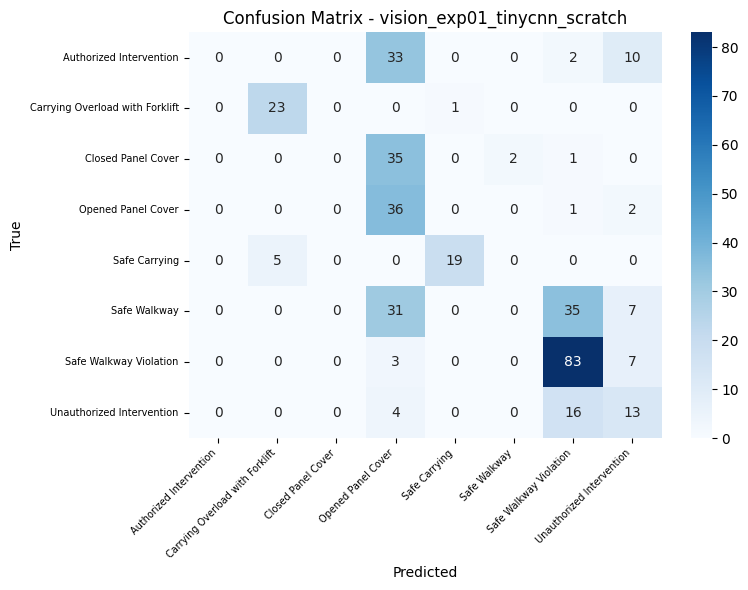

[SAVE] weights -> /content/drive/MyDrive/SAMS/models/vision/safe_unsafe/vision_exp01_tinycnn_scratch/model.pt
[SAVE] metadata -> /content/drive/MyDrive/SAMS/models/vision/safe_unsafe/vision_exp01_tinycnn_scratch/metadata.json
[SAVE] ledger -> /content/drive/MyDrive/SAMS/results/vision/safe_unsafe/vision_experiment_ledger.csv


In [52]:
register_hyperparams("vision_exp01_tinycnn_scratch", [
    {"parameter": "epochs", "value": "EPOCHS_BASELINE", "meaning": "Training epochs"},
    {"parameter": "lr", "value": "1e-3", "meaning": "AdamW learning rate"},
    {"parameter": "architecture", "value": "TinyCNN", "meaning": "From-scratch CNN"},
])

exp_id = "vision_exp01_tinycnn_scratch"
approach = "Baseline CNN from scratch (no pretrained weights)"

model = TinyCNN(NUM_CLASSES)
model, result = train_one_experiment(
    model,
    base_loaders,
    experiment_id=exp_id,
    approach=approach,
    epochs=EPOCHS_BASELINE,
    lr=1e-3,
)
save_experiment(model, result, extra_meta={"architecture": "TinyCNN", "pretrained": False})
EXPERIMENT_RESULTS.append(result)

free_memory(model)
model = None
result = None

,value,meaning
parameter,,
epochs,EPOCHS_TRANSFER,Training epochs
lr,1e-3,Head learning rate
freeze_backbone,True,ImageNet trunk frozen


EXPERIMENT: vision_exp02_resnet18_frozen
APPROACH:   Transfer learning - ResNet18 (frozen backbone)
Epochs=8  LR=0.001  Device=cuda


[vision_exp02_resnet18_frozen] epoch 1/8:   0%|          | 0/45 [00:00<?, ?it/s]

  epoch 01 | train_loss=1.4325 | val_loss=1.1477 | val_acc=0.5754 | val_f1_macro=0.2791


[vision_exp02_resnet18_frozen] epoch 2/8:   0%|          | 0/45 [00:00<?, ?it/s]

...

  epoch 06 | train_loss=0.9296 | val_loss=1.0013 | val_acc=0.6310 | val_f1_macro=0.4559


[vision_exp02_resnet18_frozen] epoch 7/8:   0%|          | 0/45 [00:00<?, ?it/s]

  epoch 07 | train_loss=0.9126 | val_loss=0.9939 | val_acc=0.6190 | val_f1_macro=0.4354


[vision_exp02_resnet18_frozen] epoch 8/8:   0%|          | 0/45 [00:00<?, ?it/s]

  epoch 08 | train_loss=0.9058 | val_loss=0.9963 | val_acc=0.6310 | val_f1_macro=0.4559

--- Test metrics ---
Accuracy:          0.4553
Precision (macro): 0.3887
Recall (macro):    0.4682
F1 (macro):        0.3799
F1 (weighted):     0.3621
                                 precision    recall  f1-score   support

        Authorized Intervention       0.00      0.00      0.00        45
Carrying Overload with Forklift       0.69      1.00      0.81        24
             Closed Panel Cover       0.00      0.00      0.00        38
             Opened Panel Cover       0.22      1.00      0.36        39
                  Safe Carrying       1.00      0.54      0.70        24
                   Safe Walkway       0.00      0.00      0.00        73
         Safe Walkway Violation       0.65      0.87      0.75        93
      Unauthorized Intervention       0.55      0.33      0.42        33

                       accuracy                           0.46       369
                      macro 

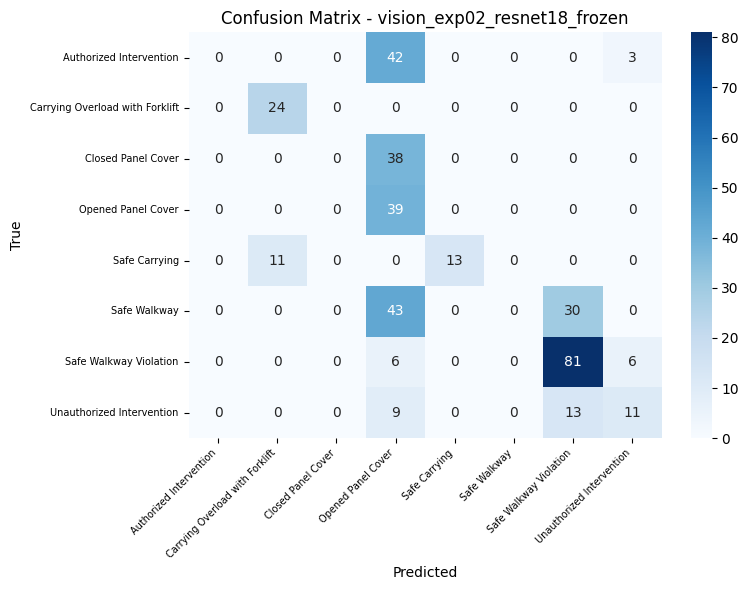

[SAVE] weights -> /content/drive/MyDrive/SAMS/models/vision/safe_unsafe/vision_exp02_resnet18_frozen/model.pt
[SAVE] metadata -> /content/drive/MyDrive/SAMS/models/vision/safe_unsafe/vision_exp02_resnet18_frozen/metadata.json
[SAVE] ledger -> /content/drive/MyDrive/SAMS/results/vision/safe_unsafe/vision_experiment_ledger.csv


In [53]:
register_hyperparams("vision_exp02_resnet18_frozen", [
    {"parameter": "epochs", "value": "EPOCHS_TRANSFER", "meaning": "Training epochs"},
    {"parameter": "lr", "value": "1e-3", "meaning": "Head learning rate"},
    {"parameter": "freeze_backbone", "value": "True", "meaning": "ImageNet trunk frozen"},
])

exp_id = "vision_exp02_resnet18_frozen"
approach = "Transfer learning - ResNet18 (frozen backbone)"

model = build_resnet18(NUM_CLASSES, freeze_backbone=True)
model, result = train_one_experiment(
    model,
    base_loaders,
    experiment_id=exp_id,
    approach=approach,
    epochs=EPOCHS_TRANSFER,
    lr=1e-3,
)
save_experiment(model, result, extra_meta={"architecture": "ResNet18", "pretrained": True, "freeze_backbone": True})
EXPERIMENT_RESULTS.append(result)

free_memory(model)
model = None
result = None

,value,meaning
parameter,,
epochs,EPOCHS_FINETUNE,Fine-tune epochs
lr,3e-5,Lower LR for full network
freeze_backbone,False,All layers trainable


EXPERIMENT: vision_exp03_resnet18_finetune
APPROACH:   Fine-tuning - ResNet18 (full network, lower LR)
Epochs=10  LR=3e-05  Device=cuda


[vision_exp03_resnet18_finetune] epoch 1/10:   0%|          | 0/45 [00:00<?, ?it/s]

  epoch 01 | train_loss=1.1713 | val_loss=0.9712 | val_acc=0.6349 | val_f1_macro=0.4771


[vision_exp03_resnet18_finetune] epoch 2/10:   0%|          | 0/45 [00:00<?, ?it/s]

...

  epoch 08 | train_loss=0.4371 | val_loss=0.7653 | val_acc=0.7421 | val_f1_macro=0.7086


[vision_exp03_resnet18_finetune] epoch 9/10:   0%|          | 0/45 [00:00<?, ?it/s]

  epoch 09 | train_loss=0.4165 | val_loss=0.7584 | val_acc=0.7500 | val_f1_macro=0.7259


[vision_exp03_resnet18_finetune] epoch 10/10:   0%|          | 0/45 [00:00<?, ?it/s]

  epoch 10 | train_loss=0.4095 | val_loss=0.7714 | val_acc=0.7421 | val_f1_macro=0.7180

--- Test metrics ---
Accuracy:          0.5962
Precision (macro): 0.7096
Recall (macro):    0.6545
F1 (macro):        0.6390
F1 (weighted):     0.5899
                                 precision    recall  f1-score   support

        Authorized Intervention       0.89      0.18      0.30        45
Carrying Overload with Forklift       1.00      1.00      1.00        24
             Closed Panel Cover       0.75      0.55      0.64        38
             Opened Panel Cover       0.44      0.69      0.54        39
                  Safe Carrying       1.00      1.00      1.00        24
                   Safe Walkway       0.43      0.63      0.51        73
         Safe Walkway Violation       0.74      0.52      0.61        93
      Unauthorized Intervention       0.42      0.67      0.52        33

                       accuracy                           0.60       369
                      macro 

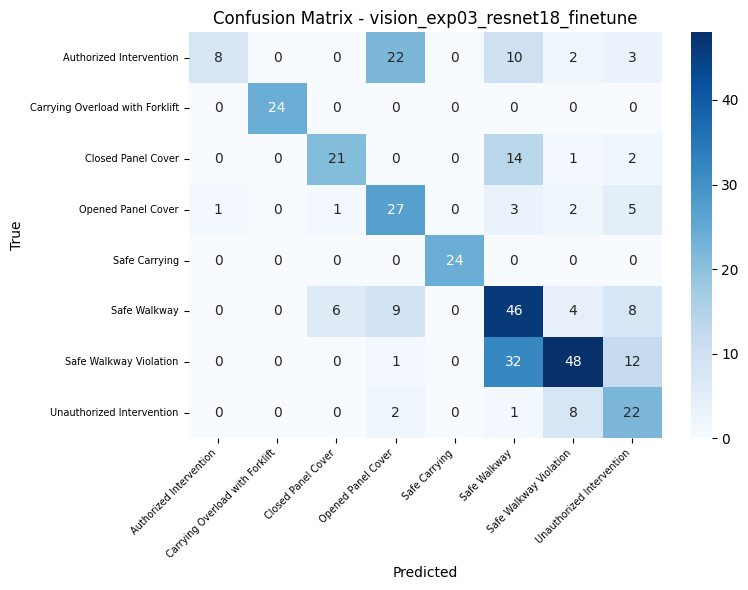

[SAVE] weights -> /content/drive/MyDrive/SAMS/models/vision/safe_unsafe/vision_exp03_resnet18_finetune/model.pt
[SAVE] metadata -> /content/drive/MyDrive/SAMS/models/vision/safe_unsafe/vision_exp03_resnet18_finetune/metadata.json
[SAVE] ledger -> /content/drive/MyDrive/SAMS/results/vision/safe_unsafe/vision_experiment_ledger.csv


In [54]:
register_hyperparams("vision_exp03_resnet18_finetune", [
    {"parameter": "epochs", "value": "EPOCHS_FINETUNE", "meaning": "Fine-tune epochs"},
    {"parameter": "lr", "value": "3e-5", "meaning": "Lower LR for full network"},
    {"parameter": "freeze_backbone", "value": "False", "meaning": "All layers trainable"},
])

exp_id = "vision_exp03_resnet18_finetune"
approach = "Fine-tuning - ResNet18 (full network, lower LR)"

model = build_resnet18(NUM_CLASSES, freeze_backbone=False)
model, result = train_one_experiment(
    model,
    base_loaders,
    experiment_id=exp_id,
    approach=approach,
    epochs=EPOCHS_FINETUNE,
    lr=3e-5,
)
save_experiment(model, result, extra_meta={"architecture": "ResNet18", "pretrained": True, "freeze_backbone": False})
EXPERIMENT_RESULTS.append(result)

free_memory(model)
model = None
result = None

,value,meaning
parameter,,
epochs,EPOCHS_TRANSFER,Training epochs
lr,1e-3,Head LR
architecture,efficientnet_b0,Frozen backbone


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 220MB/s]

EXPERIMENT: vision_exp04_efficientnet_b0_frozen
APPROACH:   Transfer learning - EfficientNet-B0 (frozen backbone)
Epochs=8  LR=0.001  Device=cuda


[vision_exp04_efficientnet_b0_frozen] epoch 1/8:   0%|          | 0/45 [00:00<?, ?it/s]

...

  epoch 06 | train_loss=0.8770 | val_loss=0.8902 | val_acc=0.6389 | val_f1_macro=0.4720


[vision_exp04_efficientnet_b0_frozen] epoch 7/8:   0%|          | 0/45 [00:00<?, ?it/s]

  epoch 07 | train_loss=0.8464 | val_loss=0.8688 | val_acc=0.6508 | val_f1_macro=0.5133


[vision_exp04_efficientnet_b0_frozen] epoch 8/8:   0%|          | 0/45 [00:00<?, ?it/s]

  epoch 08 | train_loss=0.8353 | val_loss=0.8737 | val_acc=0.6389 | val_f1_macro=0.4796

--- Test metrics ---
Accuracy:          0.5285
Precision (macro): 0.7141
Recall (macro):    0.5790
F1 (macro):        0.5234
F1 (weighted):     0.4659
                                 precision    recall  f1-score   support

        Authorized Intervention       1.00      0.04      0.09        45
Carrying Overload with Forklift       0.96      1.00      0.98        24
             Closed Panel Cover       0.90      0.47      0.62        38
             Opened Panel Cover       0.25      1.00      0.40        39
                  Safe Carrying       1.00      0.96      0.98        24
                   Safe Walkway       0.50      0.01      0.03        73
         Safe Walkway Violation       0.64      0.84      0.73        93
      Unauthorized Intervention       0.45      0.30      0.36        33

                       accuracy                           0.53       369
                      macro 

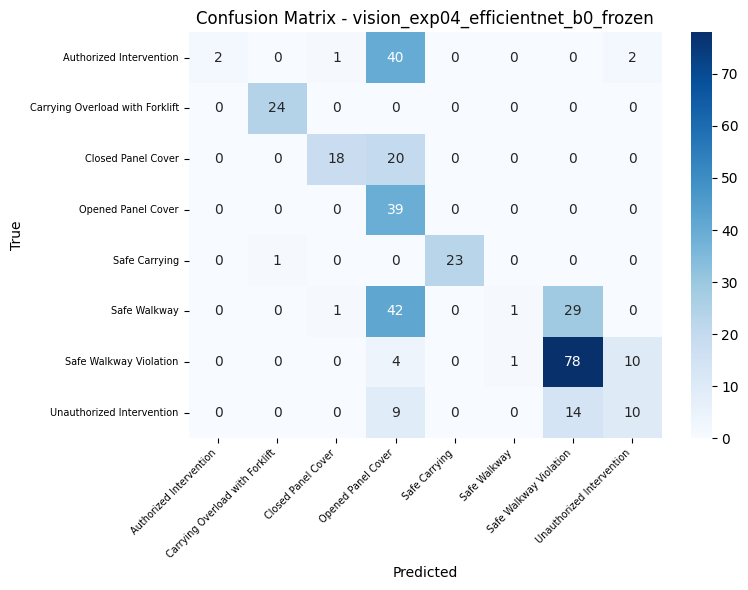

[SAVE] weights -> /content/drive/MyDrive/SAMS/models/vision/safe_unsafe/vision_exp04_efficientnet_b0_frozen/model.pt
[SAVE] metadata -> /content/drive/MyDrive/SAMS/models/vision/safe_unsafe/vision_exp04_efficientnet_b0_frozen/metadata.json
[SAVE] ledger -> /content/drive/MyDrive/SAMS/results/vision/safe_unsafe/vision_experiment_ledger.csv


In [55]:
register_hyperparams("vision_exp04_efficientnet_b0_frozen", [
    {"parameter": "epochs", "value": "EPOCHS_TRANSFER", "meaning": "Training epochs"},
    {"parameter": "lr", "value": "1e-3", "meaning": "Head LR"},
    {"parameter": "architecture", "value": "efficientnet_b0", "meaning": "Frozen backbone"},
])

exp_id = "vision_exp04_efficientnet_b0_frozen"
approach = "Transfer learning - EfficientNet-B0 (frozen backbone)"

model = build_efficientnet_b0(NUM_CLASSES, freeze_backbone=True)
model, result = train_one_experiment(
    model,
    base_loaders,
    experiment_id=exp_id,
    approach=approach,
    epochs=EPOCHS_EFFICIENT,
    lr=1e-3,
)
save_experiment(
    model, result,
    extra_meta={"architecture": "EfficientNet-B0", "pretrained": True, "freeze_backbone": True},
)
EXPERIMENT_RESULTS.append(result)

free_memory(model)
model = None
result = None

,value,meaning
parameter,,
epochs,EPOCHS_TRANSFER,Training epochs
lr,1e-3,Head LR
architecture,mobilenet_v3_small,Frozen backbone


Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 222MB/s]

EXPERIMENT: vision_exp05_mobilenet_v3_small
APPROACH:   Edge-friendly - MobileNetV3-Small (frozen backbone)
Epochs=8  LR=0.001  Device=cuda


[vision_exp05_mobilenet_v3_small] epoch 1/8:   0%|          | 0/45 [00:00<?, ?it/s]

...

  epoch 06 | train_loss=0.7771 | val_loss=0.8487 | val_acc=0.6429 | val_f1_macro=0.4874


[vision_exp05_mobilenet_v3_small] epoch 7/8:   0%|          | 0/45 [00:00<?, ?it/s]

  epoch 07 | train_loss=0.7740 | val_loss=0.8224 | val_acc=0.6587 | val_f1_macro=0.5112


[vision_exp05_mobilenet_v3_small] epoch 8/8:   0%|          | 0/45 [00:00<?, ?it/s]

  epoch 08 | train_loss=0.7595 | val_loss=0.8142 | val_acc=0.6627 | val_f1_macro=0.5145

--- Test metrics ---
Accuracy:          0.5176
Precision (macro): 0.5006
Recall (macro):    0.5646
F1 (macro):        0.4975
F1 (weighted):     0.4407
                                 precision    recall  f1-score   support

        Authorized Intervention       0.00      0.00      0.00        45
Carrying Overload with Forklift       1.00      1.00      1.00        24
             Closed Panel Cover       0.70      0.37      0.48        38
             Opened Panel Cover       0.26      0.97      0.41        39
                  Safe Carrying       1.00      1.00      1.00        24
                   Safe Walkway       0.00      0.00      0.00        73
         Safe Walkway Violation       0.64      0.87      0.74        93
      Unauthorized Intervention       0.40      0.30      0.34        33

                       accuracy                           0.52       369
                      macro 

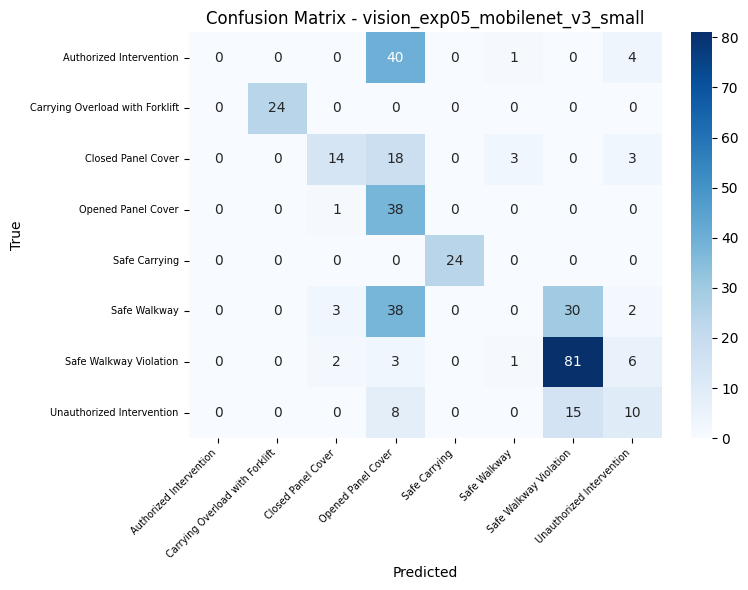

[SAVE] weights -> /content/drive/MyDrive/SAMS/models/vision/safe_unsafe/vision_exp05_mobilenet_v3_small/model.pt
[SAVE] metadata -> /content/drive/MyDrive/SAMS/models/vision/safe_unsafe/vision_exp05_mobilenet_v3_small/metadata.json
[SAVE] ledger -> /content/drive/MyDrive/SAMS/results/vision/safe_unsafe/vision_experiment_ledger.csv


In [56]:
register_hyperparams("vision_exp05_mobilenet_v3_small", [
    {"parameter": "epochs", "value": "EPOCHS_TRANSFER", "meaning": "Training epochs"},
    {"parameter": "lr", "value": "1e-3", "meaning": "Head LR"},
    {"parameter": "architecture", "value": "mobilenet_v3_small", "meaning": "Frozen backbone"},
])

exp_id = "vision_exp05_mobilenet_v3_small"
approach = "Edge-friendly - MobileNetV3-Small (frozen backbone)"

model = build_mobilenet_v3_small(NUM_CLASSES, freeze_backbone=True)
model, result = train_one_experiment(
    model,
    base_loaders,
    experiment_id=exp_id,
    approach=approach,
    epochs=EPOCHS_MOBILE,
    lr=1e-3,
)
save_experiment(
    model, result,
    extra_meta={"architecture": "MobileNetV3-Small", "pretrained": True, "freeze_backbone": True, "deployment": "edge"},
)
EXPERIMENT_RESULTS.append(result)

free_memory(model)
model = None
result = None

,value,meaning
parameter,,
epochs,EPOCHS_FINETUNE,Training epochs
class_weights,balanced,Weighted CE loss
augmentation,strong,Extra Albumentations


Class weights: {'Authorized Intervention': np.float32(1.5132), 'Carrying Overload with Forklift': np.float32(0.7451), 'Closed Panel Cover': np.float32(2.1857), 'Opened Panel Cover': np.float32(0.2851), 'Safe Carrying': np.float32(1.8214), 'Safe Walkway': np.float32(0.8129), 'Safe Walkway Violation': np.float32(0.2251), 'Unauthorized Intervention': np.float32(0.4115)}
EXPERIMENT: vision_exp06_efficientnet_robust
APPROACH:   Robust training - EfficientNet-B0 fine-tune + class weights + strong aug + weighted sampler
Epochs=10  LR=3e-05  Device=cuda


[vision_exp06_efficientnet_robust] epoch 1/10:   0%|          | 0/45 [00:00<?, ?it/s]

  epoch 01 | train_loss=1.8404 | val_loss=2.0332 | val_acc=0.1468 | val_f1_macro=0.1472


[vision_exp06_efficientnet_robust] epoch 2/10:   0%|          | 0/45 [00:00<?, ?it/s]

...

[vision_exp06_efficientnet_robust] epoch 9/10:   0%|          | 0/45 [00:00<?, ?it/s]

  epoch 09 | train_loss=0.8796 | val_loss=1.8968 | val_acc=0.2460 | val_f1_macro=0.3803


[vision_exp06_efficientnet_robust] epoch 10/10:   0%|          | 0/45 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e3ef17b36a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e3ef17b36a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

  epoch 10 | train_loss=0.8869 | val_loss=1.9105 | val_acc=0.2421 | val_f1_macro=0.3800

--- Test metrics ---
Accuracy:          0.4038
Precision (macro): 0.4471
Recall (macro):    0.5277
F1 (macro):        0.4560
F1 (weighted):     0.3374
                                 precision    recall  f1-score   support

        Authorized Intervention       0.65      0.49      0.56        45
Carrying Overload with Forklift       1.00      0.96      0.98        24
             Closed Panel Cover       0.26      1.00      0.41        38
             Opened Panel Cover       0.00      0.00      0.00        39
                  Safe Carrying       0.96      1.00      0.98        24
                   Safe Walkway       0.27      0.41      0.33        73
         Safe Walkway Violation       0.00      0.00      0.00        93
      Unauthorized Intervention       0.44      0.36      0.40        33

                       accuracy                           0.40       369
                      macro 

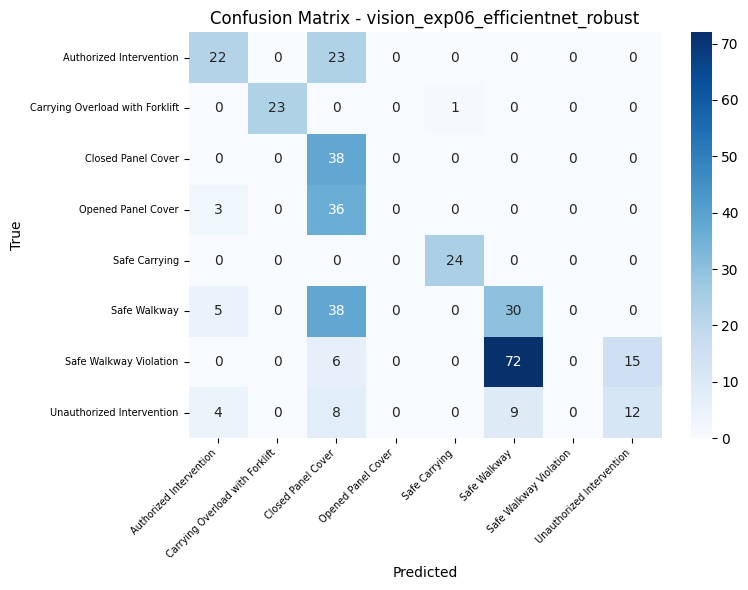

[SAVE] weights -> /content/drive/MyDrive/SAMS/models/vision/safe_unsafe/vision_exp06_efficientnet_robust/model.pt
[SAVE] metadata -> /content/drive/MyDrive/SAMS/models/vision/safe_unsafe/vision_exp06_efficientnet_robust/metadata.json
[SAVE] ledger -> /content/drive/MyDrive/SAMS/results/vision/safe_unsafe/vision_experiment_ledger.csv


In [57]:
register_hyperparams("vision_exp06_efficientnet_robust", [
    {"parameter": "epochs", "value": "EPOCHS_FINETUNE", "meaning": "Training epochs"},
    {"parameter": "class_weights", "value": "balanced", "meaning": "Weighted CE loss"},
    {"parameter": "augmentation", "value": "strong", "meaning": "Extra Albumentations"},
])

exp_id = "vision_exp06_efficientnet_robust"
approach = "Robust training - EfficientNet-B0 fine-tune + class weights + strong aug + weighted sampler"

robust_loaders = make_loaders(
    frame_manifest,
    train_transform=strong_train_tfms,
    use_weighted_sampler=True,
)

# Inverse-frequency class weights from train split
train_counts = robust_loaders["train_df"]["label_idx"].value_counts().reindex(range(NUM_CLASSES), fill_value=0)
weights = (1.0 / train_counts.clip(lower=1)).values.astype(np.float32)
weights = weights / weights.sum() * NUM_CLASSES
class_weights = torch.tensor(weights, dtype=torch.float32)
print("Class weights:", dict(zip(CLASS_NAMES, weights.round(4))))

model = build_efficientnet_b0(NUM_CLASSES, freeze_backbone=False)
model, result = train_one_experiment(
    model,
    robust_loaders,
    experiment_id=exp_id,
    approach=approach,
    epochs=EPOCHS_ROBUST,
    lr=3e-5,
    class_weights=class_weights,
)
save_experiment(
    model, result,
    extra_meta={
        "architecture": "EfficientNet-B0",
        "pretrained": True,
        "freeze_backbone": False,
        "class_weights": weights.tolist(),
        "strong_augmentation": True,
        "weighted_sampler": True,
    },
)
EXPERIMENT_RESULTS.append(result)

free_memory(model, robust_loaders)
model = None
result = None
robust_loaders = None

## 6. Compare experiments and promote best model

In [58]:
# Prefer ledger on Drive (survives re-runs / partial sessions)
ledger_path = RESULTS_DIR / "vision_experiment_ledger.csv"
if ledger_path.exists():
    comparison_df = pd.read_csv(ledger_path)
else:
    comparison_df = pd.DataFrame([
        {
            "experiment_id": r["experiment_id"],
            "approach": r["approach"],
            "accuracy": r["test_metrics"]["accuracy"],
            "precision_macro": r["test_metrics"]["precision_macro"],
            "recall_macro": r["test_metrics"]["recall_macro"],
            "f1_macro": r["test_metrics"]["f1_macro"],
            "f1_weighted": r["test_metrics"]["f1_weighted"],
            "best_val_f1_macro": r["best_val_f1_macro"],
            "epochs": r["epochs"],
            "elapsed_sec": r["elapsed_sec"],
        }
        for r in EXPERIMENT_RESULTS
    ])

comparison_df = comparison_df.sort_values("f1_macro", ascending=False).reset_index(drop=True)
comparison_path = RESULTS_DIR / "vision_comparison.csv"
comparison_df.to_csv(comparison_path, index=False)

display_cols = [
    "experiment_id", "approach", "accuracy",
    "precision_macro", "recall_macro", "f1_macro", "f1_weighted",
]
save_table(comparison_df[display_cols].set_index("experiment_id").round(4), "vision_comparison")

best = comparison_df.iloc[0]
print("Best experiment:", best["experiment_id"])
print("  Approach:", best["approach"])
print("  Accuracy:", round(best["accuracy"], 4))
print("  F1-macro:", round(best["f1_macro"], 4))
print("  F1-weighted:", round(best["f1_weighted"], 4))

,approach,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted
experiment_id,,,,,,
vision_exp03_resnet18_finetune,"Fine-tuning - ResNet18 (full network, lower LR)",0.5962,0.7096,0.6545,0.6390,0.5899
vision_exp04_efficientnet_b0_frozen,Transfer learning - EfficientNet-B0 (frozen ba...,0.5285,0.7141,0.5790,0.5234,0.4659
vision_exp05_mobilenet_v3_small,Edge-friendly - MobileNetV3-Small (frozen back...,0.5176,0.5006,0.5646,0.4975,0.4407
vision_exp06_efficientnet_robust,Robust training - EfficientNet-B0 fine-tune + ...,0.4038,0.4471,0.5277,0.4560,0.3374
vision_exp01_tinycnn_scratch,Baseline CNN from scratch (no pretrained weights),0.4715,0.3700,0.4949,0.4032,0.3692
vision_exp02_resnet18_frozen,Transfer learning - ResNet18 (frozen backbone),0.4553,0.3887,0.4682,0.3799,0.3621


Best experiment: vision_exp03_resnet18_finetune
  Approach: Fine-tuning - ResNet18 (full network, lower LR)
  Accuracy: 0.5962
  F1-macro: 0.639
  F1-weighted: 0.5899


In [60]:
comparison_df = comparison_df.sort_values("f1_macro", ascending=False)
save_table(comparison_df, "experiment_comparison")
best = comparison_df.iloc[0]
winner_id = best["experiment_id"]
print("Winner:", winner_id)

import shutil

src_dir = MODELS_DIR / winner_id
shutil.copy2(src_dir / "model.pt", MODELS_DIR / "best.pt")
with open(src_dir / "metadata.json") as f:
    meta = json.load(f)
meta["promoted_from"] = winner_id
meta["selection_metric"] = "test_f1_macro"
with open(MODELS_DIR / "metadata.json", "w") as f:
    json.dump(meta, f, indent=2)

cm = confusion_df_from_metrics(meta["test_metrics"])
save_table(cm, "confusion_best")

print("Promoted best.pt to", MODELS_DIR)

,experiment_id,approach,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,best_val_f1_macro,epochs,lr,elapsed_sec,weights_path,metadata_path,timestamp_utc
0,vision_exp03_resnet18_finetune,"Fine-tuning - ResNet18 (full network, lower LR)",0.596206,0.709627,0.654456,0.638984,0.589928,0.739219,10,0.00003,257.693737,/content/drive/MyDrive/SAMS/models/vision/safe...,/content/drive/MyDrive/SAMS/models/vision/safe...,2026-10-08T14:40:37.901381+00:00
1,vision_exp04_efficientnet_b0_frozen,Transfer learning - EfficientNet-B0 (frozen ba...,0.528455,0.714053,0.578988,0.523441,0.465903,0.513304,8,0.00100,218.951051,/content/drive/MyDrive/SAMS/models/vision/safe...,/content/drive/MyDrive/SAMS/models/vision/safe...,2026-10-08T14:45:18.476165+00:00
2,vision_exp05_mobilenet_v3_small,Edge-friendly - MobileNetV3-Small (frozen back...,0.517615,0.500616,0.564597,0.497544,0.440725,0.514497,8,0.00100,222.152261,/content/drive/MyDrive/SAMS/models/vision/safe...,/content/drive/MyDrive/SAMS/models/vision/safe...,2026-10-08T14:49:51.993720+00:00
3,vision_exp06_efficientnet_robust,Robust training - EfficientNet-B0 fine-tune + ...,0.403794,0.447101,0.527727,0.455973,0.337428,0.392436,10,0.00003,264.650875,/content/drive/MyDrive/SAMS/models/vision/safe...,/content/drive/MyDrive/SAMS/models/vision/safe...,2026-10-08T14:54:57.826940+00:00
4,vision_exp01_tinycnn_scratch,Baseline CNN from scratch (no pretrained weights),0.471545,0.369967,0.494936,0.403221,0.369159,0.453093,12,0.00100,275.582826,/content/drive/MyDrive/SAMS/models/vision/safe...,/content/drive/MyDrive/SAMS/models/vision/safe...,2026-10-08T14:31:07.477318+00:00
5,vision_exp02_resnet18_frozen,Transfer learning - ResNet18 (frozen backbone),0.455285,0.388660,0.468246,0.379876,0.362060,0.467663,8,0.00100,210.063980,/content/drive/MyDrive/SAMS/models/vision/safe...,/content/drive/MyDrive/SAMS/models/vision/safe...,2026-10-08T14:35:38.841622+00:00


Winner: vision_exp03_resnet18_finetune


,Authorized Intervention,Carrying Overload with Forklift,Closed Panel Cover,Opened Panel Cover,Safe Carrying,Safe Walkway,Safe Walkway Violation,Unauthorized Intervention
Authorized Intervention,8,0,0,22,0,10,2,3
Carrying Overload with Forklift,0,24,0,0,0,0,0,0
Closed Panel Cover,0,0,21,0,0,14,1,2
Opened Panel Cover,1,0,1,27,0,3,2,5
Safe Carrying,0,0,0,0,24,0,0,0
Safe Walkway,0,0,6,9,0,46,4,8
Safe Walkway Violation,0,0,0,1,0,32,48,12
Unauthorized Intervention,0,0,0,2,0,1,8,22


Promoted best.pt to /content/drive/MyDrive/SAMS/models/vision/safe_unsafe


## 7. Limitations

**Limitations**

1. **Video frames, not live SAMS cameras.** Domain shift to your site is unknown until you fine-tune on local clips.
2. **Clip-level splits.** Multiple frames from one video are correlated; holdout by video reduces but does not remove all leakage between train and val.
3. **Class imbalance.** Rare unsafe behaviours may still score low recall even with class weights in experiment 6.
4. **No production wiring.** Django does not load this model; deployment would need a new inference module and UI contract.
5. **Compute.** Full fine-tuning (experiment 3) is slower than frozen-backbone runs; early stopping mitigates cost but does not guarantee optimal convergence.